# Loan Default Prediction - Home Credit

**Goal:** predict which loan applicants will have payment difficulties (`TARGET = 1`) so the lender can reduce credit losses, and turn the predictions into a **business decision** (approve / review / decline).

**Approach:** audit and clean the data, explore it, build a Logistic Regression baseline, test two engineered feature groups, compare LightGBM and XGBoost (plus a tuned LightGBM), check **over/under-fitting**, calibrate the scores, translate them into money and risk bands, explain them with SHAP and audit them for fairness.

**Key challenge:** only ~8% of loans default (imbalanced), so accuracy is misleading; the notebook relies on ROC-AUC, PR-AUC, KS, recall and precision.

**Key design decisions (and why)**
1. **Honest evaluation:** train / validation / test split; every choice (feature set, model, tuning, threshold, calibration) is made on validation, the test set is touched only for final numbers.
2. **No protected attribute in the model:** `CODE_GENDER` is excluded from scoring (`EXCLUDE_FROM_MODEL`) and the effect is audited in Section 17.
3. **Fit diagnostics:** train-vs-validation gaps, a complexity sweep and a learning curve (Section 12b) show whether the model over- or under-fits.
4. **Business numbers are illustrative:** LGD and margin are assumptions; compare policies with each other rather than reading the absolute money values.
5. **Reusable artefact:** the final model, preprocessing and calibrator are saved and re-scored on raw rows (Section 18).

The headline numbers are printed by the last code cell (Section 19) from the actual run, so the text can never disagree with the results.

## 0. Imports and settings
Libraries for data handling, plotting, preprocessing, the models and the evaluation metrics. `SAMPLE_FRAC` lets you do a quick dry run on a fraction of the data (keep it `None` for the final run).

In [107]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             precision_score, recall_score, f1_score, balanced_accuracy_score,
                             matthews_corrcoef, confusion_matrix, accuracy_score, brier_score_loss)
from lightgbm import LGBMClassifier, early_stopping
import lightgbm as lgb
import xgboost as xgb
import joblib
from scipy.stats import spearmanr
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

RANDOM_STATE = 42
SAMPLE_FRAC = None     # e.g. 0.1 for a quick dry run on 10% of the data; None = full data
N_BOOT = 200           # bootstrap resamples for confidence intervals
CV_FOLDS = 5           # stratified k-fold CV (on train + validation)
N_TUNE_TRIALS = 25     # random-search trials for LightGBM (lower it for a quick run)
EXCLUDE_FROM_MODEL = ['CODE_GENDER']   # protected attribute: NOT used for scoring (audited in section 17)
MODEL_PATH = 'loan_default_model.joblib'

## 1. Load data
Load the application table and check its size and the target balance. The file is searched in the notebook folder first, so the notebook runs on any machine.

In [109]:
CANDIDATE_PATHS = [Path('Dataset2.csv'), Path('data/Dataset2.csv'), Path('/mnt/user-data/uploads/Dataset2.csv'),
                   Path(r'C:\Users\Lenovo\Desktop\assessment data\assessment data\Dataset2.csv')]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Dataset2.csv not found - put it next to the notebook or edit CANDIDATE_PATHS.')

df = pd.read_csv(DATA_PATH)
if SAMPLE_FRAC:
    df = df.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE)
print('Loaded from:', DATA_PATH)
print(df.shape)
df.head()

Loaded from: C:\Users\Lenovo\Desktop\assessment data\assessment data\Dataset2.csv
(307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,...,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,...,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.028663,-19932,-3038,-4311.0,-3458,NaN,1,1,0,...,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [110]:
print(df['TARGET'].value_counts())
print(df['TARGET'].value_counts(normalize=True).round(4))

TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64


**Note on the target (from the data dictionary):** `TARGET = 1` means a late payment of more than *X* days on at least one of the first *Y* instalments. *X* and *Y* are not disclosed, so "default" here means "early payment difficulties", not necessarily a final write-off.

## 2. Data audit
Check duplicates, data types, missing values and suspicious values before changing anything.

In [113]:
print('Duplicate loan IDs:', df['SK_ID_CURR'].duplicated().sum())
print(df.dtypes.value_counts())

Duplicate loan IDs: 0
float64    65
int64      41
object     16
Name: count, dtype: int64


In [114]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
print('Columns with any missing values:', (missing_pct > 0).sum())
print('Columns with more than 60% missing:', (missing_pct > 60).sum())
missing_pct[missing_pct > 0].head(25).round(1)

Columns with any missing values: 67
Columns with more than 60% missing: 17


COMMONAREA_MEDI             69.9
COMMONAREA_AVG              69.9
COMMONAREA_MODE             69.9
NONLIVINGAPARTMENTS_MODE    69.4
NONLIVINGAPARTMENTS_AVG     69.4
NONLIVINGAPARTMENTS_MEDI    69.4
FONDKAPREMONT_MODE          68.4
LIVINGAPARTMENTS_MODE       68.4
LIVINGAPARTMENTS_AVG        68.4
LIVINGAPARTMENTS_MEDI       68.4
FLOORSMIN_AVG               67.8
FLOORSMIN_MODE              67.8
FLOORSMIN_MEDI              67.8
YEARS_BUILD_MEDI            66.5
YEARS_BUILD_MODE            66.5
YEARS_BUILD_AVG             66.5
OWN_CAR_AGE                 66.0
LANDAREA_MEDI               59.4
LANDAREA_MODE               59.4
LANDAREA_AVG                59.4
BASEMENTAREA_MEDI           58.5
BASEMENTAREA_AVG            58.5
BASEMENTAREA_MODE           58.5
EXT_SOURCE_1                56.4
NONLIVINGAREA_MODE          55.2
dtype: float64

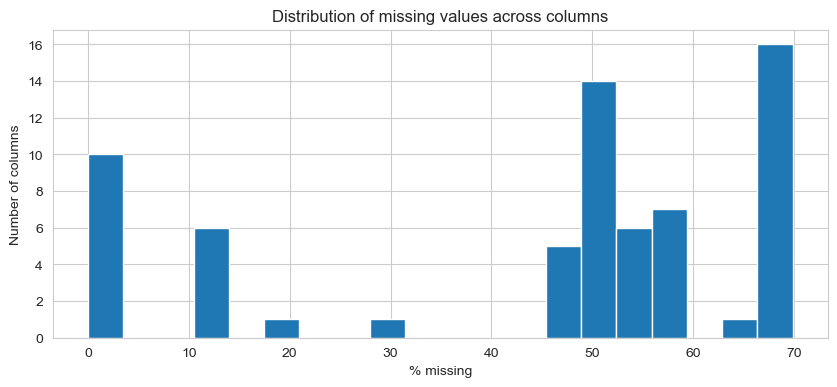

In [115]:
fig, ax = plt.subplots(figsize=(10, 4))
missing_pct[missing_pct > 0].plot.hist(bins=20, ax=ax)
ax.set_xlabel('% missing')
ax.set_ylabel('Number of columns')
ax.set_title('Distribution of missing values across columns')
plt.show()

In [116]:
print('DAYS_EMPLOYED == 365243:', (df['DAYS_EMPLOYED'] == 365243).sum())
print(df.loc[df['DAYS_EMPLOYED'] == 365243, 'NAME_INCOME_TYPE'].value_counts())

DAYS_EMPLOYED == 365243: 55374
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64


In [117]:
print(df['CODE_GENDER'].value_counts())
df.loc[df['CODE_GENDER'] == 'XNA', ['CODE_GENDER', 'NAME_INCOME_TYPE', 'AMT_INCOME_TOTAL', 'TARGET']]

CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64


,CODE_GENDER,NAME_INCOME_TYPE,AMT_INCOME_TOTAL,TARGET
35657,XNA,Working,207000.0,0
38566,XNA,Working,157500.0,0
83382,XNA,Working,135000.0,0
189640,XNA,Commercial associate,247500.0,0


In [118]:
df[['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']].describe().round(0)

,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
count,307511.0,307511.0,307511.0,307499.0,307233.0
mean,0.0,168798.0,599026.0,27109.0,538396.0
std,1.0,237123.0,402491.0,14494.0,369446.0
min,0.0,25650.0,45000.0,1616.0,40500.0
25%,0.0,112500.0,270000.0,16524.0,238500.0
50%,0.0,147150.0,513531.0,24903.0,450000.0
75%,1.0,202500.0,808650.0,34596.0,679500.0
max,19.0,117000000.0,4050000.0,258026.0,4050000.0


**Two extra checks suggested by the data dictionary**
1. `AMT_GOODS_PRICE` is documented as "for consumer loans" - check how it behaves per contract type before using it in ratios.
2. The building features come in three versions (`_AVG`, `_MODE`, `_MEDI`) of the same measure - check how redundant they are.

In [120]:
print('Missing AMT_GOODS_PRICE by contract type:')
print(df.groupby('NAME_CONTRACT_TYPE')['AMT_GOODS_PRICE'].apply(lambda s: s.isna().mean()).round(4))
print('\nShare of loans where goods price == credit amount:')
print((df['AMT_GOODS_PRICE'] == df['AMT_CREDIT']).groupby(df['NAME_CONTRACT_TYPE']).mean().round(3))

Missing AMT_GOODS_PRICE by contract type:
NAME_CONTRACT_TYPE
Cash loans         0.0000
Revolving loans    0.0095
Name: AMT_GOODS_PRICE, dtype: float64

Share of loans where goods price == credit amount:
NAME_CONTRACT_TYPE
Cash loans         0.286
Revolving loans    0.979
dtype: float64


In [121]:
num_building = [c for c in df.select_dtypes('number').columns if c.endswith(('_AVG', '_MODE', '_MEDI'))]
bases = sorted({c.rsplit('_', 1)[0] for c in num_building})
print(len(num_building), 'numeric building columns for', len(bases), 'distinct measures')
for suffix in ['_AVG', '_MODE']:
    pairs = [(b + suffix, b + '_MEDI') for b in bases if (b + suffix) in df.columns and (b + '_MEDI') in df.columns]
    corr = pd.Series({a: df[a].corr(df[m]) for a, m in pairs})
    print(f'Correlation {suffix} vs _MEDI: min = {corr.min():.2f}, median = {corr.median():.2f}, n = {len(corr)}')

43 numeric building columns for 15 distinct measures
Correlation _AVG vs _MEDI: min = 0.99, median = 1.00, n = 14
Correlation _MODE vs _MEDI: min = 0.96, median = 0.98, n = 14


## 3. Data cleaning
- Fix the 365243 placeholder (and keep a flag `DAYS_EMPLOYED_ANOM`), drop the 4 `XNA` gender rows.
- Keep only the `_MEDI` version of each numeric building feature (the `_AVG` / `_MODE` copies are almost identical, so they only add noise and collinearity).
- **Keep** the columns with a lot of missing values: tree models can use them and the pipeline adds a missing-value indicator for each (deleting them would throw away information: the EDA shows that being missing is itself related to default).
- Convert days to years.
- **Outliers are flagged but not deleted**: a lender cannot refuse to score a client because the income is high. Extreme values are capped later, inside the pipeline, using percentiles learned on the training set only.
Remaining missing values are imputed inside the modelling pipeline so nothing leaks from the test set.

In [123]:
df_clean = df.copy()
df_clean['DAYS_EMPLOYED_ANOM'] = (df_clean['DAYS_EMPLOYED'] == 365243).astype(int)
df_clean['DAYS_EMPLOYED'] = df_clean['DAYS_EMPLOYED'].replace(365243, np.nan)
df_clean = df_clean[df_clean['CODE_GENDER'] != 'XNA']

In [124]:
redundant_cols = [c for c in num_building
                  if c.endswith(('_AVG', '_MODE')) and (c.rsplit('_', 1)[0] + '_MEDI') in df_clean.columns]
df_clean = df_clean.drop(columns=redundant_cols)
print('Dropped redundant building columns:', len(redundant_cols))
print('Columns with more than 60% missing that are KEPT:',
      int(((df_clean.isna().mean() * 100) > 60).sum()))
print('Shape now:', df_clean.shape)

Dropped redundant building columns: 28
Columns with more than 60% missing that are KEPT: 7
Shape now: (307507, 95)


In [125]:
df_clean['AGE_YEARS'] = -df_clean['DAYS_BIRTH'] / 365
df_clean['YEARS_EMPLOYED'] = -df_clean['DAYS_EMPLOYED'] / 365
df_clean = df_clean.drop(columns=['DAYS_BIRTH', 'DAYS_EMPLOYED'])

In [126]:
outlier_cols = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']
outlier_mask = pd.Series(False, index=df_clean.index)
for col in outlier_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outlier_mask |= (df_clean[col] < q1 - 3 * iqr) | (df_clean[col] > q3 + 3 * iqr)
outlier_mask |= df_clean['CNT_CHILDREN'] > 10

print('Outlier rows (flagged only, NOT removed):', outlier_mask.sum(), f'({outlier_mask.mean():.2%})')
print('Default rate in outliers:', round(df_clean.loc[outlier_mask, 'TARGET'].mean(), 4))
print('Default rate in the rest:', round(df_clean.loc[~outlier_mask, 'TARGET'].mean(), 4))
print('Final shape:', df_clean.shape)

Outlier rows (flagged only, NOT removed): 4635 (1.51%)
Default rate in outliers: 0.0442
Default rate in the rest: 0.0813
Final shape: (307507, 95)


## 4. Exploratory data analysis (EDA)
Only one table (`application_data`) was provided, so the analysis looks at how each group of features relates to `TARGET`.
The red dashed line is the overall default rate; anything above it is riskier than average.

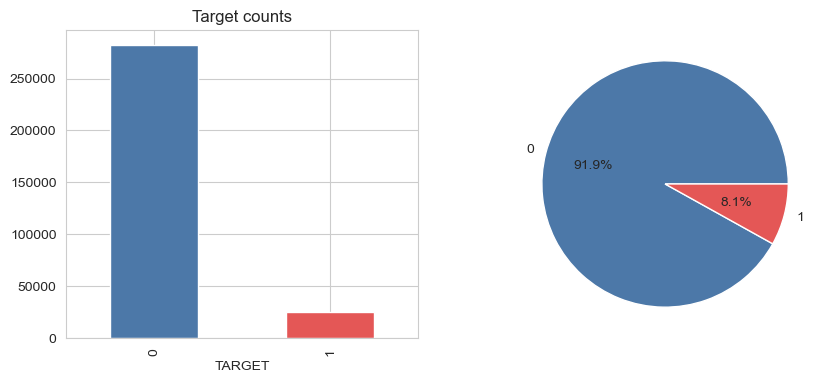

In [128]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
df_clean['TARGET'].value_counts().plot.bar(ax=ax[0], color=['#4C78A8', '#E45756'])
ax[0].set_title('Target counts')
df_clean['TARGET'].value_counts(normalize=True).plot.pie(ax=ax[1], autopct='%1.1f%%', colors=['#4C78A8', '#E45756'])
ax[1].set_ylabel('')
plt.show()

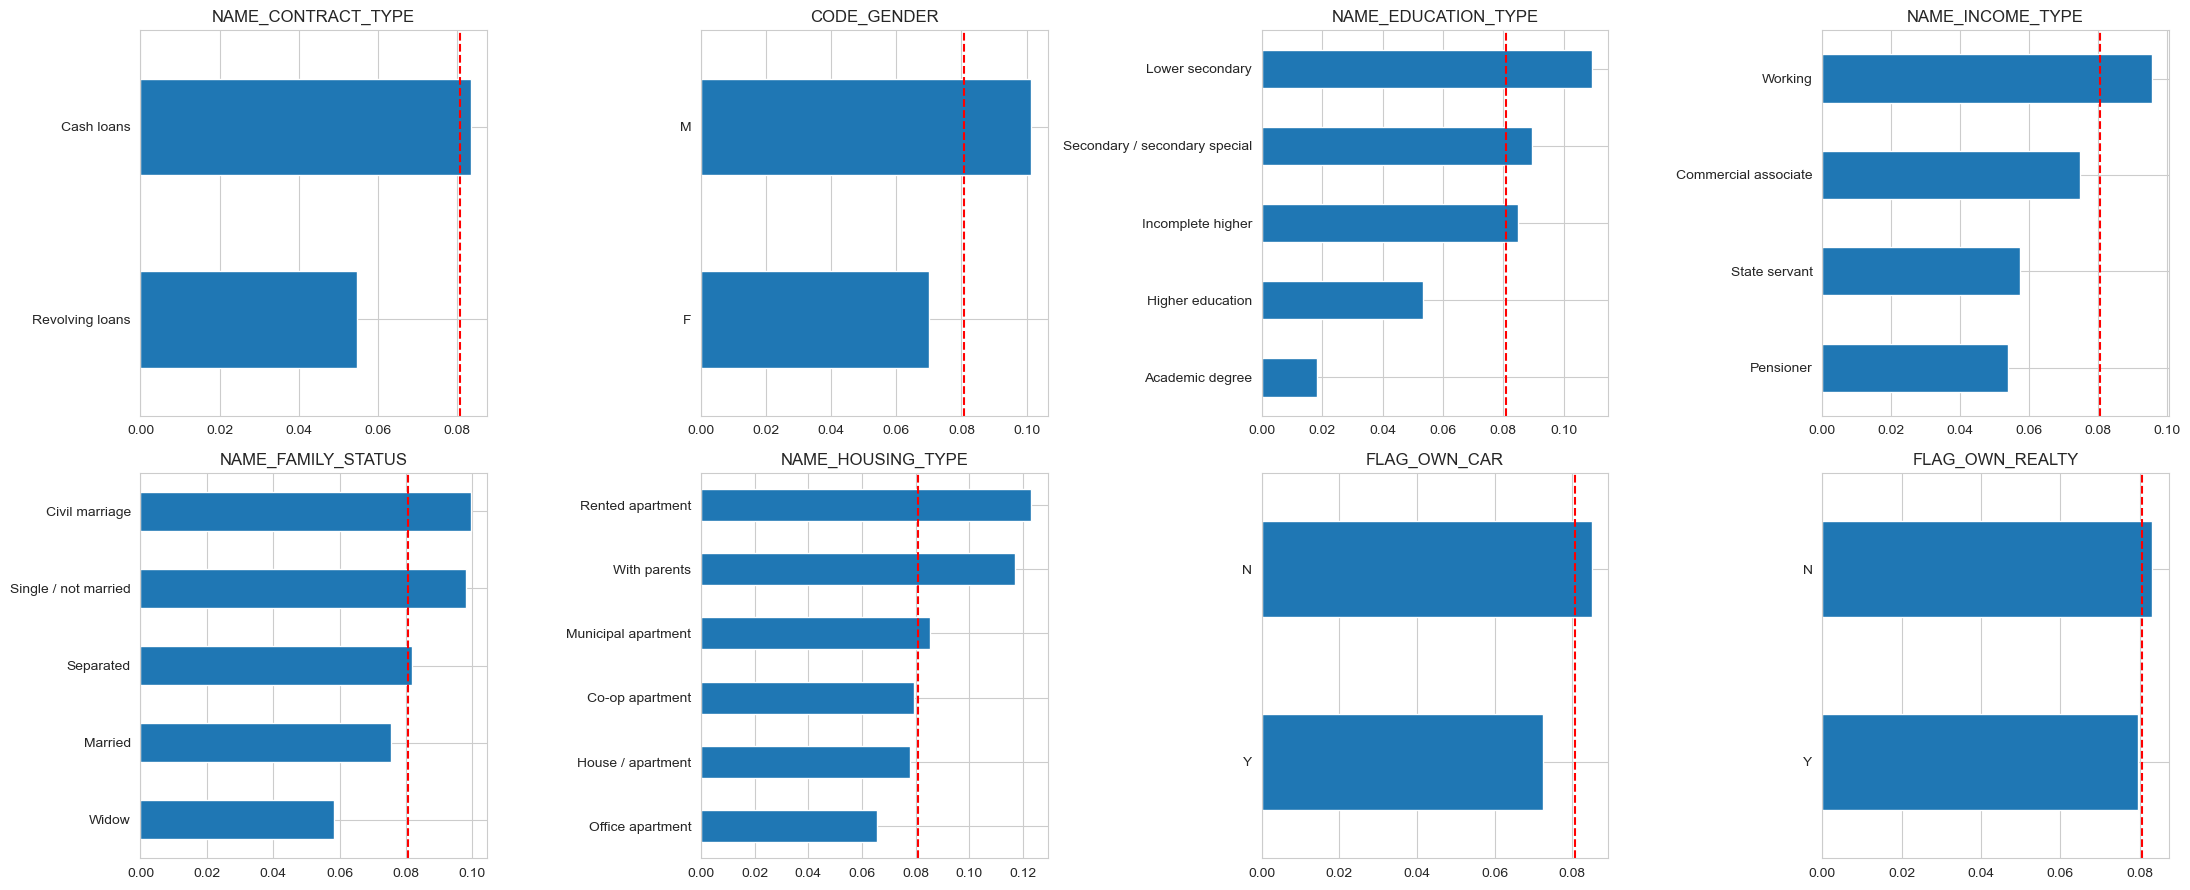

In [129]:
cat_features = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE',
                'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']
overall_rate = df_clean['TARGET'].mean()
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, col in zip(axes.ravel(), cat_features):
    stats = df_clean.groupby(col)['TARGET'].agg(['mean', 'size'])
    stats[stats['size'] >= 100]['mean'].sort_values().plot.barh(ax=ax)
    ax.axvline(overall_rate, color='red', linestyle='--')
    ax.set_title(col)
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

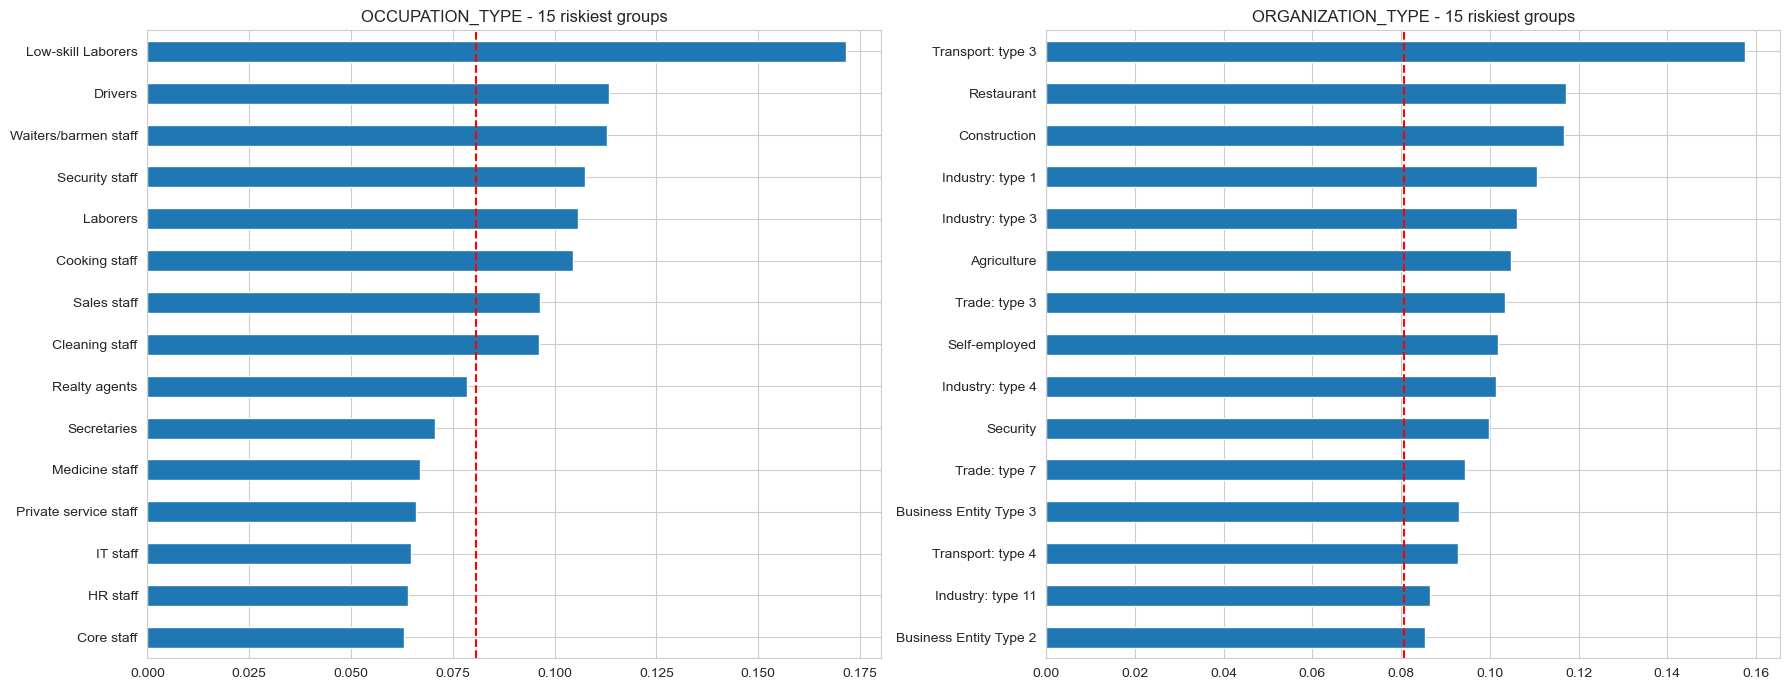

In [130]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, col in zip(axes, ['OCCUPATION_TYPE', 'ORGANIZATION_TYPE']):
    stats = df_clean.groupby(col)['TARGET'].agg(['mean', 'size'])
    stats[stats['size'] >= 500]['mean'].sort_values().tail(15).plot.barh(ax=ax)
    ax.axvline(overall_rate, color='red', linestyle='--')
    ax.set_title(f'{col} - 15 riskiest groups')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

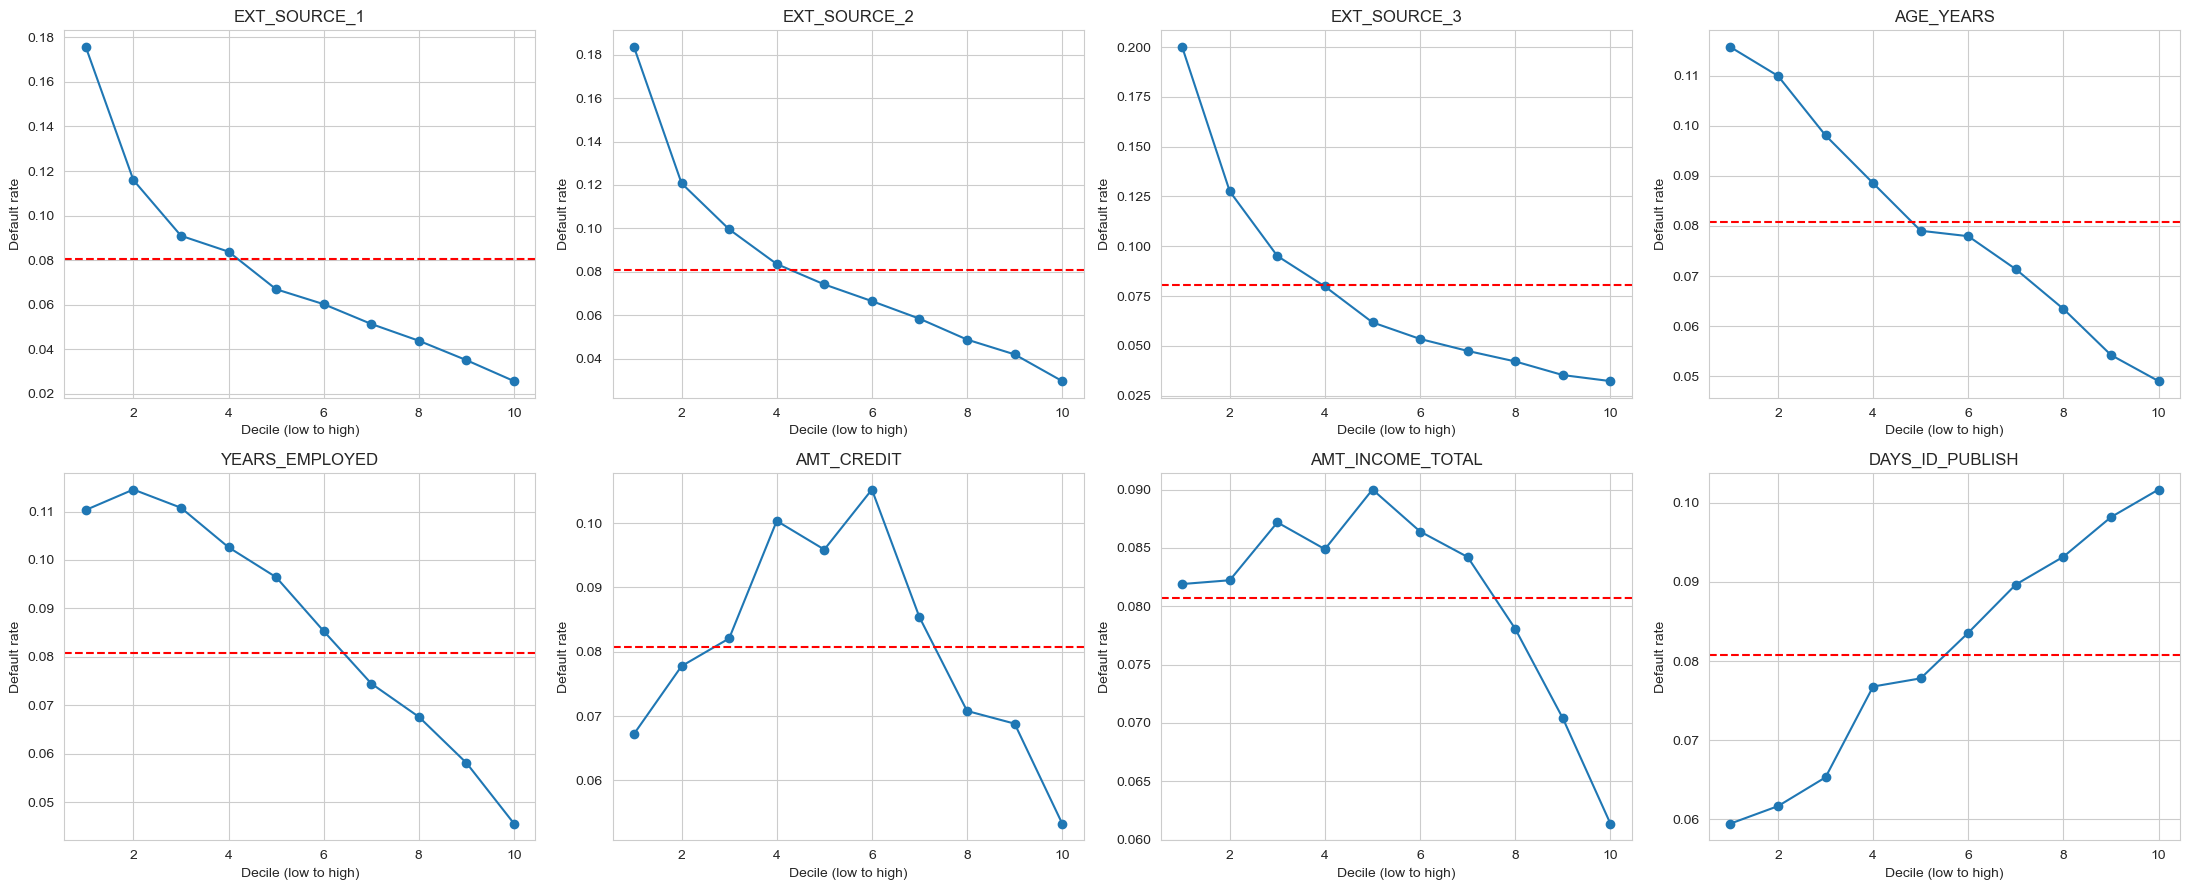

In [131]:
num_features = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS',
                'YEARS_EMPLOYED', 'AMT_CREDIT', 'AMT_INCOME_TOTAL', 'DAYS_ID_PUBLISH']
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, col in zip(axes.ravel(), num_features):
    deciles = pd.qcut(df_clean[col], 10, duplicates='drop')
    rate = df_clean.groupby(deciles, observed=True)['TARGET'].mean()
    ax.plot(range(1, len(rate) + 1), rate.values, marker='o')
    ax.axhline(overall_rate, color='red', linestyle='--')
    ax.set_title(col)
    ax.set_xlabel('Decile (low to high)')
    ax.set_ylabel('Default rate')
plt.tight_layout()
plt.show()

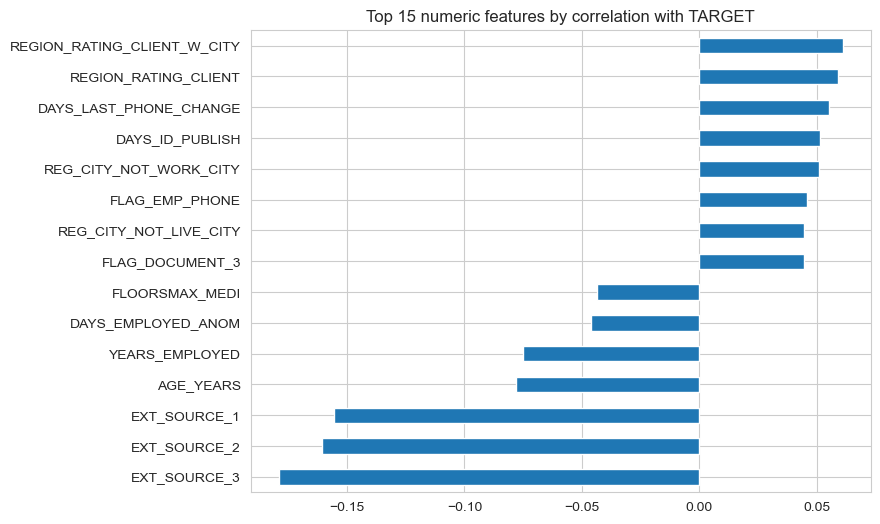

In [132]:
corr = df_clean.select_dtypes(include='number').corr()['TARGET'].drop('TARGET')
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15)
top_corr.sort_values().plot.barh(figsize=(8, 6), title='Top 15 numeric features by correlation with TARGET')
plt.show()

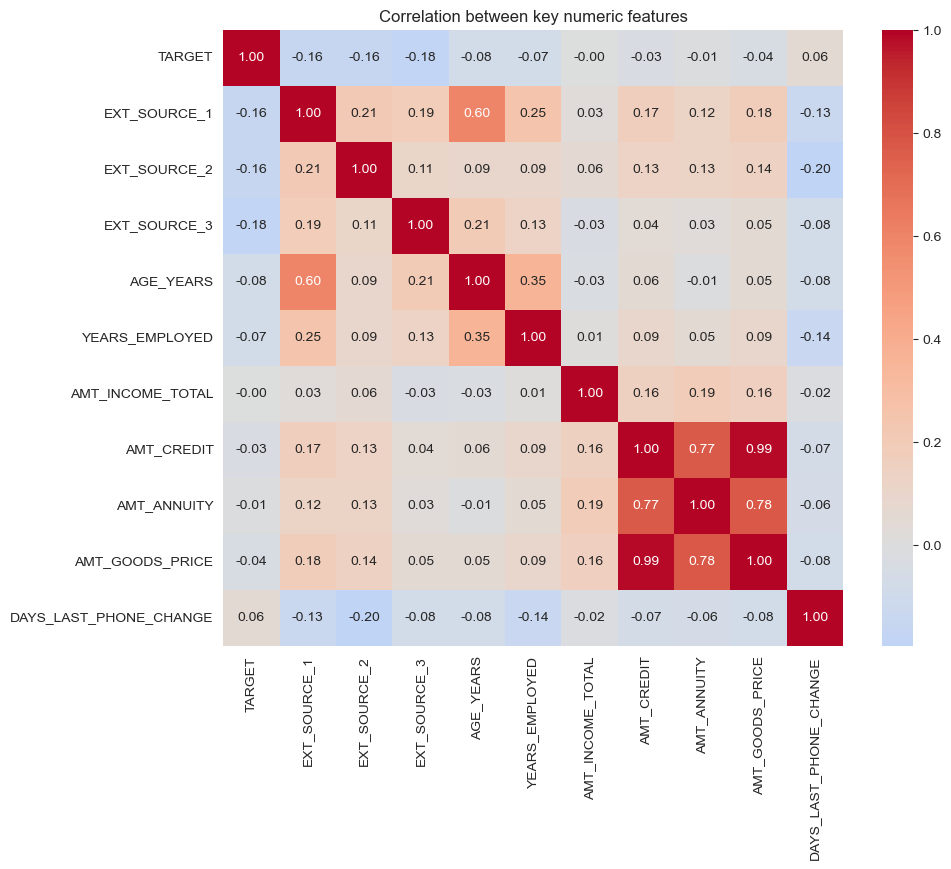

In [133]:
heat_cols = ['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS', 'YEARS_EMPLOYED',
             'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'DAYS_LAST_PHONE_CHANGE']
plt.figure(figsize=(10, 8))
sns.heatmap(df_clean[heat_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation between key numeric features')
plt.show()

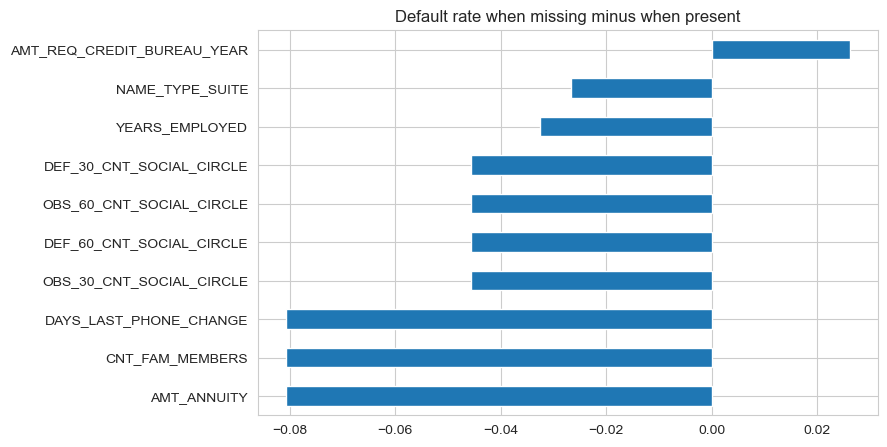

In [134]:
miss_gap = {}
for col in df_clean.columns[df_clean.isna().any()]:
    rates = df_clean.groupby(df_clean[col].isna())['TARGET'].mean()
    if True in rates.index and False in rates.index:
        miss_gap[col] = rates[True] - rates[False]
miss_gap = pd.Series(miss_gap).sort_values(key=abs, ascending=False).head(10)
miss_gap.sort_values().plot.barh(figsize=(8, 5), title='Default rate when missing minus when present')
plt.show()

In [135]:
print(df_clean.groupby('DAYS_EMPLOYED_ANOM')['TARGET'].agg(['mean', 'size']).round(4))
print()
print(df_clean.groupby('NAME_INCOME_TYPE')['TARGET'].agg(['mean', 'size']).round(4).sort_values('mean'))

                      mean    size
DAYS_EMPLOYED_ANOM                
0                   0.0866  252133
1                   0.0540   55374

                        mean    size
NAME_INCOME_TYPE                    
Businessman           0.0000      10
Student               0.0000      18
Pensioner             0.0539   55362
State servant         0.0575   21703
Commercial associate  0.0748   71616
Working               0.0959  158771
Unemployed            0.3636      22
Maternity leave       0.4000       5


### Key business insights from the EDA
The cell below turns the charts into plain statements (all numbers are computed from the data, groups with fewer than 1,000 clients are ignored).

In [137]:
def extremes(col, min_size=1000):
    s = df_clean.groupby(col)['TARGET'].agg(['mean', 'size'])
    s = s[s['size'] >= min_size]['mean'].sort_values()
    return s.index[0], s.iloc[0], s.index[-1], s.iloc[-1]

print(f'Overall default rate: {overall_rate:.1%}\n')
for col in ['NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'OCCUPATION_TYPE', 'NAME_CONTRACT_TYPE', 'NAME_FAMILY_STATUS']:
    lo, lo_r, hi, hi_r = extremes(col)
    print(f"- {col}: safest group '{lo}' ({lo_r:.1%}) vs riskiest '{hi}' ({hi_r:.1%}) -> {hi_r / lo_r:.1f}x")

ext2 = pd.qcut(df_clean['EXT_SOURCE_2'], 10, labels=False, duplicates='drop')
r_low, r_high = df_clean.loc[ext2 == ext2.min(), 'TARGET'].mean(), df_clean.loc[ext2 == ext2.max(), 'TARGET'].mean()
print(f'- EXT_SOURCE_2: lowest-score decile defaults at {r_low:.1%} vs {r_high:.1%} in the highest ({r_low / r_high:.1f}x)')

age_band = pd.cut(df_clean['AGE_YEARS'], [0, 30, 40, 50, 60, 120])
age_rate = df_clean.groupby(age_band, observed=True)['TARGET'].mean()
print(f'- Age: {age_rate.iloc[0]:.1%} for clients under 30 vs {age_rate.iloc[-1]:.1%} for clients over 60')

ratio = df_clean['AMT_CREDIT'] / df_clean['AMT_INCOME_TOTAL']
rd = pd.qcut(ratio, 10, labels=False, duplicates='drop')
print(f'- Credit/income ratio: top decile {df_clean.loc[rd == rd.max(), "TARGET"].mean():.1%} vs bottom decile {df_clean.loc[rd == rd.min(), "TARGET"].mean():.1%}')

m1 = df_clean['EXT_SOURCE_1'].isna()
print(f'- Missing EXT_SOURCE_1: {df_clean.loc[m1, "TARGET"].mean():.1%} default when missing vs {df_clean.loc[~m1, "TARGET"].mean():.1%} when present')
print(f'- Pensioner-type employment anomaly (DAYS_EMPLOYED=365243): {df_clean.loc[df_clean["DAYS_EMPLOYED_ANOM"] == 1, "TARGET"].mean():.1%} default')

Overall default rate: 8.1%

- NAME_INCOME_TYPE: safest group 'Pensioner' (5.4%) vs riskiest 'Working' (9.6%) -> 1.8x
- NAME_EDUCATION_TYPE: safest group 'Higher education' (5.4%) vs riskiest 'Lower secondary' (10.9%) -> 2.0x
- OCCUPATION_TYPE: safest group 'Accountants' (4.8%) vs riskiest 'Low-skill Laborers' (17.2%) -> 3.6x
- NAME_CONTRACT_TYPE: safest group 'Revolving loans' (5.5%) vs riskiest 'Cash loans' (8.3%) -> 1.5x
- NAME_FAMILY_STATUS: safest group 'Widow' (5.8%) vs riskiest 'Civil marriage' (9.9%) -> 1.7x
- EXT_SOURCE_2: lowest-score decile defaults at 18.4% vs 3.0% in the highest (6.2x)
- Age: 11.5% for clients under 30 vs 4.9% for clients over 60
- Credit/income ratio: top decile 7.1% vs bottom decile 6.9%
- Missing EXT_SOURCE_1: 8.5% default when missing vs 7.5% when present
- Pensioner-type employment anomaly (DAYS_EMPLOYED=365243): 5.4% default


## 5. Train / validation / test split and preprocessing
Stratified split (64% train, 16% validation, 20% test) keeps the 8% default rate in every part.
Validation is used for early stopping, hyper-parameter tuning, **model selection**, calibration and threshold choice; the test set is used only for the final results.

The preprocessing pipeline (fitted on train only):
1. **Capper** - caps extreme values of amounts, counts and ratios at the 0.1% / 99.9% percentiles of the training set (instead of deleting rows).
2. Numbers: median imputation **with missing-value indicators**, then scaling. Categories: missing becomes its own category, then one-hot encoding.

**Excluded attribute:** columns listed in `EXCLUDE_FROM_MODEL` (by default `CODE_GENDER`) are removed from the feature matrix `X`. They stay in `df_clean` so that Section 17 can still audit the decisions by gender.

In [139]:
X = df_clean.drop(columns=['TARGET', 'SK_ID_CURR'] + EXCLUDE_FROM_MODEL)
print('Features used by the model:', X.shape[1], '| excluded:', EXCLUDE_FROM_MODEL)
y = df_clean['TARGET']
train_full_idx, test_idx = train_test_split(X.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
train_idx, val_idx = train_test_split(train_full_idx, test_size=0.2, stratify=y.loc[train_full_idx], random_state=RANDOM_STATE)
y_train, y_val, y_test = y.loc[train_idx], y.loc[val_idx], y.loc[test_idx]
print(len(train_idx), len(val_idx), len(test_idx))
print(y_train.mean().round(4), y_val.mean().round(4), y_test.mean().round(4))

Features used by the model: 92 | excluded: ['CODE_GENDER']
196804 49201 61502
0.0807 0.0807 0.0807


In [140]:
CAP_COLS = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS',
            'AMT_REQ_CREDIT_BUREAU_QRT', 'AMT_REQ_CREDIT_BUREAU_YEAR',
            'OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE',
            # engineered features (created in section 9)
            'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO', 'CREDIT_TERM', 'GOODS_CREDIT_RATIO', 'INCOME_PER_PERSON',
            'EMPLOYED_AGE_RATIO', 'BUREAU_ENQUIRIES_TOTAL', 'BUREAU_RECENT_ENQUIRIES']


class Capper(BaseEstimator, TransformerMixin):
    """Winsorise continuous columns at percentiles learned on the training data only."""
    def __init__(self, cols=None, lower=0.001, upper=0.999):
        self.cols = cols
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        cols = [c for c in (self.cols or []) if c in X.columns]
        self.caps_ = {c: (X[c].quantile(self.lower), X[c].quantile(self.upper)) for c in cols}
        return self

    def transform(self, X):
        X = X.copy()
        for c, (lo, hi) in self.caps_.items():
            X[c] = X[c].clip(lo, hi)
        return X


def make_preprocessor():
    num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True)),
                         ('scaler', StandardScaler())])
    cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
                         ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=0.005, sparse_output=False))])
    columns = ColumnTransformer([('num', num_pipe, make_column_selector(dtype_include=np.number)),
                                 ('cat', cat_pipe, make_column_selector(dtype_exclude=np.number))])
    return Pipeline([('caps', Capper(cols=CAP_COLS)), ('pre', columns)])


def prepare(features):
    pipe = make_preprocessor()
    A_train = pipe.fit_transform(features.loc[train_idx]).astype(np.float32)
    A_val = pipe.transform(features.loc[val_idx]).astype(np.float32)
    A_test = pipe.transform(features.loc[test_idx]).astype(np.float32)
    return A_train, A_val, A_test, pipe.named_steps['pre'].get_feature_names_out(), pipe

In [141]:
A_train, A_val, A_test, feature_names, base_pipe = prepare(X)
print(A_train.shape, A_val.shape, A_test.shape)

(196804, 214) (49201, 214) (61502, 214)


## 6. Why accuracy is not enough
A model that predicts "no default" for everyone gets very high accuracy but catches zero defaulters.
This is why the metrics below are ranked by importance for imbalanced data.

In [143]:
dummy = DummyClassifier(strategy='most_frequent').fit(A_train, y_train)
dummy_pred = dummy.predict(A_test)
print('Accuracy :', round(accuracy_score(y_test, dummy_pred), 4))
print('Recall   :', round(recall_score(y_test, dummy_pred), 4))
print('ROC-AUC  :', round(roc_auc_score(y_test, dummy.predict_proba(A_test)[:, 1]), 4))

Accuracy : 0.9193
Recall   : 0.0
ROC-AUC  : 0.5


## 7. Baseline model: Logistic Regression
Logistic Regression on the original (cleaned) features only, with `class_weight='balanced'` so the minority class (defaults) is not ignored.
This is the reference point every later model must beat.

In [145]:
baseline = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)
baseline.fit(A_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

## 8. Evaluation metrics
Ranking metrics (ROC-AUC, PR-AUC, KS, Gini) do not depend on a threshold.
Recall, precision, F1, balanced accuracy and MCC need a threshold, which is chosen on the validation set by maximising F1.
Accuracy is calculated last, only for reference. (Section 15 chooses a *business* threshold instead.)

In [147]:
def best_threshold(y_true, proba):
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    return thresholds[np.argmax(f1[:-1])]

In [148]:
def evaluate(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    fpr, tpr, _ = roc_curve(y_true, proba)
    auc = roc_auc_score(y_true, proba)
    return {
        'ROC_AUC': auc,
        'PR_AUC': average_precision_score(y_true, proba),
        'KS': (tpr - fpr).max(),
        'Gini': 2 * auc - 1,
        'Recall': recall_score(y_true, pred),
        'Precision': precision_score(y_true, pred, zero_division=0),
        'F1': f1_score(y_true, pred),
        'Balanced_Acc': balanced_accuracy_score(y_true, pred),
        'MCC': matthews_corrcoef(y_true, pred),
        'Accuracy': accuracy_score(y_true, pred),
    }

In [149]:
base_val_proba = baseline.predict_proba(A_val)[:, 1]
base_threshold = best_threshold(y_val, base_val_proba)
base_test_proba = baseline.predict_proba(A_test)[:, 1]
baseline_metrics = evaluate(y_test, base_test_proba, base_threshold)
print('Threshold chosen on validation:', round(base_threshold, 4))
pd.Series(baseline_metrics).round(4)

Threshold chosen on validation: 0.6384


ROC_AUC         0.7494
PR_AUC          0.2314
KS              0.3692
Gini            0.4988
Recall          0.4560
Precision       0.2195
F1              0.2964
Balanced_Acc    0.6568
MCC             0.2287
Accuracy        0.8252
dtype: float64

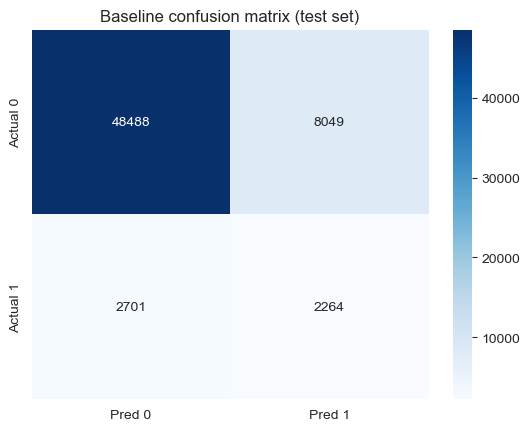

In [150]:
cm = confusion_matrix(y_test, (base_test_proba >= base_threshold).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Baseline confusion matrix (test set)')
plt.show()

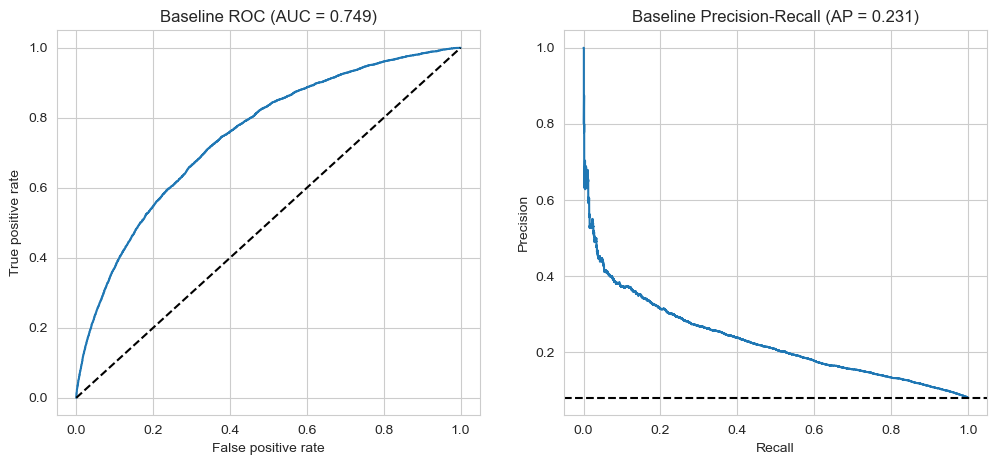

In [151]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
fpr, tpr, _ = roc_curve(y_test, base_test_proba)
ax[0].plot(fpr, tpr)
ax[0].plot([0, 1], [0, 1], 'k--')
ax[0].set_title(f"Baseline ROC (AUC = {baseline_metrics['ROC_AUC']:.3f})")
ax[0].set_xlabel('False positive rate')
ax[0].set_ylabel('True positive rate')
prec, rec, _ = precision_recall_curve(y_test, base_test_proba)
ax[1].plot(rec, prec)
ax[1].axhline(y_test.mean(), color='k', linestyle='--')
ax[1].set_title(f"Baseline Precision-Recall (AP = {baseline_metrics['PR_AUC']:.3f})")
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
plt.show()

## 9. Feature engineering: two added feature groups
**Group 1 - financial ratios:** how heavy the loan is relative to income, term and employment history (affordability signals).
**Group 2 - risk and stability signals:** combined external scores, bureau enquiries (total and recent), documents provided, address mismatches, social-circle default ratio, how recently the client changed phone, ID document or registration relative to age, and a night-time application flag.

Many of these ratios are standard for this dataset, so the point of the experiment is not novelty but evidence: **does each group improve the models here?** The effect of each group is measured on validation and test (Section 11) and groups that add nothing are reported as such.

Notes from the data dictionary: the bureau-enquiry windows do not overlap (each one excludes the previous window), so summing them is valid; `OBS_*` is the number of observed people in the social circle and `DEF_*` how many of them defaulted, so `DEF/OBS` is a meaningful ratio.

In [153]:
def add_financial_features(d):
    d = d.copy()
    d['CREDIT_INCOME_RATIO'] = d['AMT_CREDIT'] / d['AMT_INCOME_TOTAL']
    d['ANNUITY_INCOME_RATIO'] = d['AMT_ANNUITY'] / d['AMT_INCOME_TOTAL']
    d['CREDIT_TERM'] = d['AMT_CREDIT'] / d['AMT_ANNUITY']
    d['GOODS_CREDIT_RATIO'] = d['AMT_GOODS_PRICE'] / d['AMT_CREDIT']
    d['INCOME_PER_PERSON'] = d['AMT_INCOME_TOTAL'] / d['CNT_FAM_MEMBERS']
    d['EMPLOYED_AGE_RATIO'] = d['YEARS_EMPLOYED'] / d['AGE_YEARS']
    return d.replace([np.inf, -np.inf], np.nan)

In [154]:
ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
bureau_cols = [c for c in X.columns if c.startswith('AMT_REQ_CREDIT_BUREAU')]
recent_bureau_cols = [c for c in bureau_cols if c.endswith(('_HOUR', '_DAY', '_WEEK', '_MON'))]
doc_cols = [c for c in X.columns if c.startswith('FLAG_DOCUMENT')]
address_cols = ['REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION',
                'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY']

def add_risk_features(d):
    d = d.copy()
    d['EXT_MEAN'] = d[ext_cols].mean(axis=1)
    d['EXT_MIN'] = d[ext_cols].min(axis=1)
    d['EXT_PRODUCT'] = d[ext_cols].prod(axis=1, min_count=1)
    d['EXT_MISSING_COUNT'] = d[ext_cols].isna().sum(axis=1)
    d['BUREAU_ENQUIRIES_TOTAL'] = d[bureau_cols].sum(axis=1, min_count=1)
    d['BUREAU_RECENT_ENQUIRIES'] = d[recent_bureau_cols].sum(axis=1, min_count=1)
    d['DOCUMENTS_PROVIDED'] = d[doc_cols].sum(axis=1)
    d['ADDRESS_MISMATCH_COUNT'] = d[address_cols].sum(axis=1)
    d['SOCIAL_DEFAULT_RATIO_30'] = d['DEF_30_CNT_SOCIAL_CIRCLE'] / d['OBS_30_CNT_SOCIAL_CIRCLE']
    d['PHONE_CHANGE_AGE_RATIO'] = (-d['DAYS_LAST_PHONE_CHANGE'] / 365) / d['AGE_YEARS']
    d['ID_PUBLISH_AGE_RATIO'] = (-d['DAYS_ID_PUBLISH'] / 365) / d['AGE_YEARS']
    d['REGISTRATION_AGE_RATIO'] = (-d['DAYS_REGISTRATION'] / 365) / d['AGE_YEARS']
    d['APPLIED_AT_NIGHT'] = ((d['HOUR_APPR_PROCESS_START'] >= 22) | (d['HOUR_APPR_PROCESS_START'] <= 5)).astype(int)
    return d.replace([np.inf, -np.inf], np.nan)

In [155]:
feature_builders = {
    'Base': lambda d: d,
    '+Financial': add_financial_features,
    '+Financial+Risk': lambda d: add_risk_features(add_financial_features(d)),
}
check = add_risk_features(add_financial_features(X))
new_cols = [c for c in check.columns if c not in X.columns]
print(len(new_cols), 'new features')
pd.concat([check[new_cols], y], axis=1).corr()['TARGET'].drop('TARGET').sort_values().round(3)

19 new features


EXT_MEAN                  -0.222
EXT_MIN                   -0.185
EXT_PRODUCT               -0.140
EMPLOYED_AGE_RATIO        -0.068
GOODS_CREDIT_RATIO        -0.065
PHONE_CHANGE_AGE_RATIO    -0.034
CREDIT_TERM               -0.032
ID_PUBLISH_AGE_RATIO      -0.011
BUREAU_RECENT_ENQUIRIES   -0.011
REGISTRATION_AGE_RATIO    -0.009
CREDIT_INCOME_RATIO       -0.008
INCOME_PER_PERSON         -0.007
APPLIED_AT_NIGHT           0.009
BUREAU_ENQUIRIES_TOTAL     0.011
ANNUITY_INCOME_RATIO       0.014
DOCUMENTS_PROVIDED         0.017
EXT_MISSING_COUNT          0.028
SOCIAL_DEFAULT_RATIO_30    0.042
ADDRESS_MISMATCH_COUNT     0.045
Name: TARGET, dtype: float64

In [156]:
# cache so that only one prepared matrix set is kept in memory at a time
_cache = {'Base': (A_train, A_val, A_test, feature_names, base_pipe)}

def get_matrices(fs_name):
    if fs_name not in _cache:
        _cache.clear()
        _cache[fs_name] = prepare(feature_builders[fs_name](X))
    return _cache[fs_name]

## 10. Model comparison: 3 models x 3 feature sets + tuned LightGBM
Each model is trained on each feature set. LightGBM and XGBoost use `scale_pos_weight` for the imbalance and early stopping on the validation set.
Logistic Regression on the Base features is the baseline already trained above, so it is reused instead of retrained.

**Selection rule (fixed in advance):** the best combination is the one with the highest **validation** ROC-AUC. The test set is never used to choose anything.

In [158]:
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

LGB_PARAMS = dict(n_estimators=400, learning_rate=0.08, num_leaves=31, subsample=0.8, subsample_freq=1,
                  colsample_bytree=0.7, min_child_samples=100, scale_pos_weight=scale_pos, metric='auc',
                  importance_type='gain', random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
XGB_PARAMS = dict(n_estimators=400, learning_rate=0.08, max_depth=5, subsample=0.8, colsample_bytree=0.7,
                  min_child_weight=10, scale_pos_weight=scale_pos, tree_method='hist', eval_metric='auc',
                  random_state=RANDOM_STATE, n_jobs=-1)

def make_models():
    return {
        'LogReg': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
        'LightGBM': LGBMClassifier(**LGB_PARAMS),
        'XGBoost': XGBClassifier(**XGB_PARAMS, early_stopping_rounds=40),
    }

def fit_model(model, A_tr, y_tr, A_va, y_va):
    if isinstance(model, LGBMClassifier):
        model.fit(A_tr, y_tr, eval_set=[(A_va, y_va)], callbacks=[early_stopping(40, first_metric_only=True, verbose=False)])
    elif isinstance(model, XGBClassifier):
        model.fit(A_tr, y_tr, eval_set=[(A_va, y_va)], verbose=False)
    else:
        model.fit(A_tr, y_tr)
    return model

In [159]:
results, store = [], {}

def register(fs_name, model_name, model, A_va, A_te):
    val_proba = model.predict_proba(A_va)[:, 1]
    threshold = best_threshold(y_val, val_proba)
    proba = model.predict_proba(A_te)[:, 1]
    val_auc = roc_auc_score(y_val, val_proba)
    results.append({'Features': fs_name, 'Model': model_name, 'Val_ROC_AUC': val_auc, **evaluate(y_test, proba, threshold)})
    store[(fs_name, model_name)] = {'model': model, 'val_proba': val_proba, 'proba': proba,
                                    'threshold': threshold, 'val_auc': val_auc}

register('Base', 'LogReg', baseline, A_val, A_test)

for fs_name in feature_builders:
    A_tr, A_va, A_te, names, _ = get_matrices(fs_name)
    for model_name, model in make_models().items():
        if (fs_name, model_name) in store:
            continue
        model = fit_model(model, A_tr, y_train, A_va, y_val)
        register(fs_name, model_name, model, A_va, A_te)
        print('done:', fs_name, model_name)

done: Base LightGBM
done: Base XGBoost
done: +Financial LogReg
done: +Financial LightGBM
done: +Financial XGBoost
done: +Financial+Risk LogReg
done: +Financial+Risk LightGBM
done: +Financial+Risk XGBoost


### Hyper-parameter tuning (LightGBM)
Random search (`N_TUNE_TRIALS` distinct configurations, duplicates removed) on the feature set where LightGBM is best on validation. Every trial uses early stopping on the validation set, and the first trial is the default configuration so the tuned model can never be worse on validation than the untuned one.
The test set is not touched during tuning. Report the tuning gain honestly: small gains are normal for boosting on tabular data (see the paired bootstrap in Section 11).

In [161]:
lgb_val = {fs: store[(fs, 'LightGBM')]['val_auc'] for fs in feature_builders}
fs_star = max(lgb_val, key=lgb_val.get)
print('Feature set used for tuning and CV:', fs_star, {k: round(v, 4) for k, v in lgb_val.items()})

A_tr, A_va, A_te, names_star, _ = get_matrices(fs_star)

search_space = {
    'learning_rate': [0.02, 0.03, 0.05, 0.08],
    'num_leaves': [15, 31, 63],
    'min_child_samples': [50, 100, 200, 400],
    'colsample_bytree': [0.3, 0.5, 0.7, 0.9],
    'subsample': [0.7, 0.8, 0.9],
    'reg_lambda': [0, 1, 5, 20],
    'reg_alpha': [0, 0.1, 1],
}
rng = np.random.RandomState(RANDOM_STATE)
candidates, seen = [{}], {()}
attempts = 0
while len(candidates) <= N_TUNE_TRIALS and attempts < 10000:
    attempts += 1
    cand = {k: v[rng.randint(len(v))] for k, v in search_space.items()}
    key = tuple(sorted(cand.items()))
    if key not in seen:
        seen.add(key)
        candidates.append(cand)
print(len(candidates), 'distinct configurations (including the default one)')

trial_rows, best_trial = [], None
for params in candidates:
    m = LGBMClassifier(**{**LGB_PARAMS, 'n_estimators': 1500, **params})
    m = fit_model(m, A_tr, y_train, A_va, y_val)
    auc = roc_auc_score(y_val, m.predict_proba(A_va)[:, 1])
    trial_rows.append({**params, 'n_trees': m.best_iteration_, 'val_auc': auc})
    if best_trial is None or auc > best_trial[0]:
        best_trial = (auc, m, params)

trials_df = pd.DataFrame(trial_rows).sort_values('val_auc', ascending=False).reset_index(drop=True)
TUNED_PARAMS = best_trial[2]
print('Best params:', TUNED_PARAMS or 'default configuration')
register(fs_star, 'LightGBM_tuned', best_trial[1], A_va, A_te)
trials_df.round(4)

Feature set used for tuning and CV: +Financial {'Base': 0.7561, '+Financial': 0.7649, '+Financial+Risk': 0.7639}
26 distinct configurations (including the default one)
Best params: {'learning_rate': 0.03, 'num_leaves': 15, 'min_child_samples': 400, 'colsample_bytree': 0.3, 'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha': 1}


,n_trees,val_auc,learning_rate,num_leaves,min_child_samples,colsample_bytree,subsample,reg_lambda,reg_alpha
0,1139,0.7684,0.03,15.0,400.0,0.3,0.7,5.0,1.0
1,694,0.7684,0.02,63.0,200.0,0.5,0.8,20.0,0.0
2,586,0.7678,0.03,31.0,400.0,0.9,0.7,0.0,0.1
3,478,0.7676,0.05,31.0,400.0,0.9,0.9,1.0,0.1
4,851,0.7675,0.02,31.0,200.0,0.7,0.8,5.0,1.0
5,1028,0.7674,0.03,15.0,400.0,0.5,0.8,1.0,0.0
6,598,0.7674,0.03,31.0,400.0,0.5,0.7,5.0,0.1
7,669,0.7674,0.02,63.0,50.0,0.9,0.7,20.0,1.0
8,406,0.7672,0.03,63.0,200.0,0.7,0.9,20.0,0.0
9,434,0.7670,0.03,31.0,100.0,0.5,0.8,5.0,1.0


## 11. Results
Results sorted by **validation** ROC-AUC (the selection criterion). The test columns are the honest, final numbers; columns are ordered by importance for an imbalanced problem and Accuracy is last on purpose.

In [163]:
results_df = pd.DataFrame(results).sort_values('Val_ROC_AUC', ascending=False).reset_index(drop=True)
results_df.round(4)

,Features,Model,Val_ROC_AUC,ROC_AUC,PR_AUC,KS,Gini,Recall,Precision,F1,Balanced_Acc,MCC,Accuracy
0,+Financial,LightGBM_tuned,0.7684,0.7713,0.2624,0.4069,0.5426,0.4248,0.2550,0.3187,0.6579,0.2521,0.8534
1,+Financial,LightGBM,0.7649,0.7676,0.2582,0.3984,0.5352,0.4471,0.2464,0.3177,0.6635,0.2519,0.8449
2,+Financial,XGBoost,0.7647,0.7677,0.2592,0.4023,0.5353,0.4363,0.2454,0.3141,0.6592,0.2474,0.8462
3,+Financial+Risk,XGBoost,0.7646,0.7661,0.2571,0.3959,0.5323,0.4727,0.2308,0.3101,0.6672,0.2452,0.8302
4,+Financial+Risk,LightGBM,0.7639,0.7664,0.2551,0.3991,0.5329,0.4459,0.2422,0.3139,0.6617,0.2477,0.8426
5,Base,XGBoost,0.7564,0.7593,0.2504,0.3855,0.5186,0.4209,0.2433,0.3084,0.6530,0.2405,0.8476
6,Base,LightGBM,0.7561,0.7581,0.2486,0.3841,0.5162,0.4443,0.2336,0.3062,0.6582,0.2390,0.8375
7,+Financial+Risk,LogReg,0.7482,0.7498,0.2351,0.3679,0.4996,0.4630,0.2162,0.2948,0.6578,0.2274,0.8212
8,+Financial,LogReg,0.7476,0.7498,0.2333,0.3696,0.4997,0.4228,0.2291,0.2972,0.6489,0.2279,0.8386
9,Base,LogReg,0.7472,0.7494,0.2314,0.3692,0.4988,0.4560,0.2195,0.2964,0.6568,0.2287,0.8252


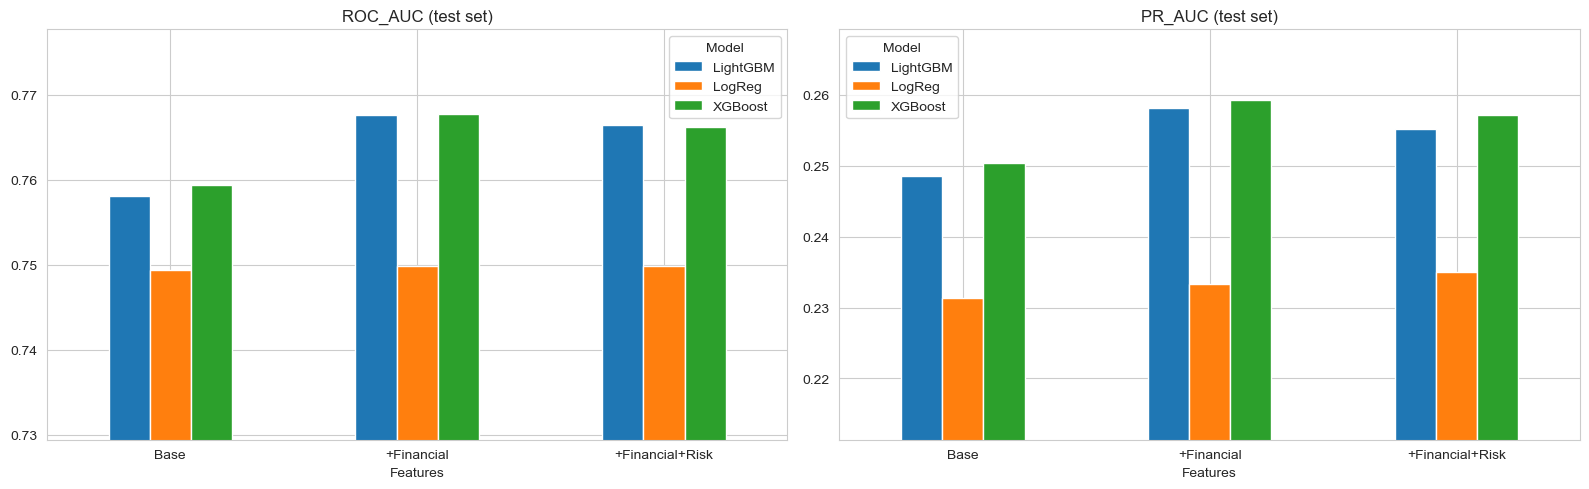

In [164]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
order = ['Base', '+Financial', '+Financial+Risk']
three = results_df[results_df['Model'].isin(['LogReg', 'LightGBM', 'XGBoost'])]
for a, metric in zip(ax, ['ROC_AUC', 'PR_AUC']):
    pivot = three.pivot(index='Features', columns='Model', values=metric).loc[order]
    pivot.plot.bar(ax=a, rot=0)
    a.set_title(f'{metric} (test set)')
    a.set_ylim(pivot.values.min() - 0.02, pivot.values.max() + 0.01)
plt.tight_layout()
plt.show()

**Effect of each feature group.** The table shows the change in test ROC-AUC against the `Base` feature set for each model, and the printout compares the groups on validation. Gains smaller than about 0.002 AUC are within noise (see the bootstrap intervals below), so they should be reported as "no clear benefit".

In [166]:
three_models = ['LogReg', 'LightGBM', 'XGBoost']
order = ['Base', '+Financial', '+Financial+Risk']
sel = results_df[results_df['Model'].isin(three_models)]
test_piv = sel.pivot(index='Features', columns='Model', values='ROC_AUC').loc[order]
val_piv = sel.pivot(index='Features', columns='Model', values='Val_ROC_AUC').loc[order]
display((test_piv - test_piv.loc['Base']).round(4))
for mname in val_piv.columns:
    d_fin = val_piv.loc['+Financial', mname] - val_piv.loc['Base', mname]
    d_risk = val_piv.loc['+Financial+Risk', mname] - val_piv.loc['+Financial', mname]
    print(f'{mname:9s} validation AUC: Financial group {d_fin:+.4f} vs Base | Risk group on top of it {d_risk:+.4f}')

Model,LightGBM,LogReg,XGBoost
Features,,,
Base,0.0000,0.0000,0.0000
+Financial,0.0095,0.0004,0.0083
+Financial+Risk,0.0083,0.0004,0.0068


LightGBM  validation AUC: Financial group +0.0088 vs Base | Risk group on top of it -0.0011
LogReg    validation AUC: Financial group +0.0003 vs Base | Risk group on top of it +0.0006
XGBoost   validation AUC: Financial group +0.0083 vs Base | Risk group on top of it -0.0001


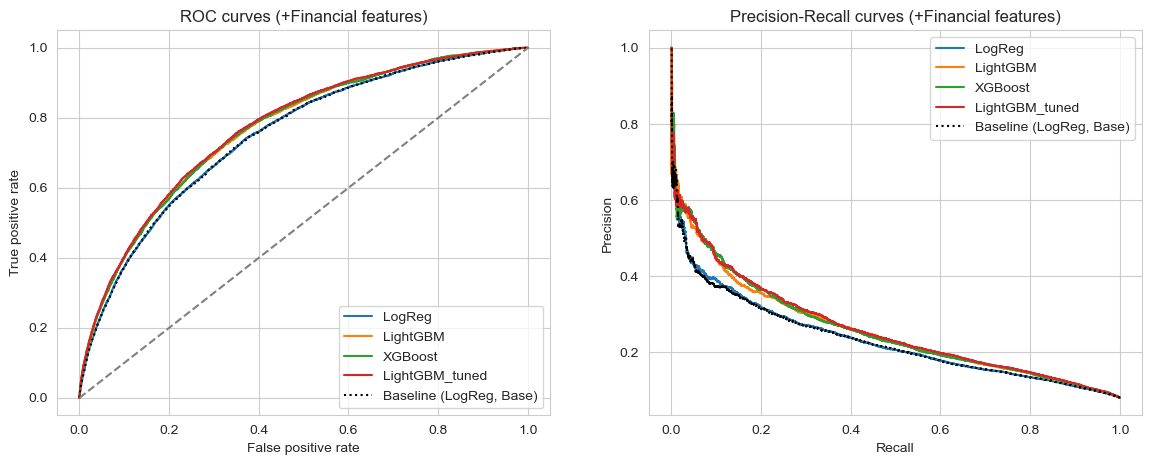

In [167]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for model_name in ['LogReg', 'LightGBM', 'XGBoost', 'LightGBM_tuned']:
    if (fs_star, model_name) not in store:
        continue
    p = store[(fs_star, model_name)]['proba']
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=model_name)
    ax[1].plot(rec, prec, label=model_name)
fpr, tpr, _ = roc_curve(y_test, base_test_proba)
prec, rec, _ = precision_recall_curve(y_test, base_test_proba)
ax[0].plot(fpr, tpr, 'k:', label='Baseline (LogReg, Base)')
ax[1].plot(rec, prec, 'k:', label='Baseline (LogReg, Base)')
ax[0].plot([0, 1], [0, 1], color='grey', linestyle='--')
ax[0].set_title(f'ROC curves ({fs_star} features)')
ax[0].set_xlabel('False positive rate')
ax[0].set_ylabel('True positive rate')
ax[1].set_title(f'Precision-Recall curves ({fs_star} features)')
ax[1].set_xlabel('Recall')
ax[1].set_ylabel('Precision')
ax[0].legend()
ax[1].legend()
plt.show()

### Is the improvement real? Bootstrap confidence intervals
The differences between the boosting models are small, so a single test number is not enough. The same bootstrap resamples of the test set are used for every model, which gives a paired 95% interval for the **gain over the baseline** (if the interval excludes 0, the gain is not noise).

In [169]:
y_arr = y_test.values
n_test = len(y_arr)
boot_rng = np.random.RandomState(RANDOM_STATE)
boot_idx = [boot_rng.randint(0, n_test, n_test) for _ in range(N_BOOT)]

def boot_aucs(p):
    return np.array([roc_auc_score(y_arr[i], p[i]) for i in boot_idx])

base_boot = boot_aucs(base_test_proba)
boot_store, rows = {}, []
for (fs, mn), e in store.items():
    b = boot_aucs(e['proba'])
    boot_store[(fs, mn)] = b
    d = b - base_boot
    lo, hi = np.percentile(d, [2.5, 97.5])
    rows.append({'Features': fs, 'Model': mn, 'Test_ROC_AUC': roc_auc_score(y_arr, e['proba']),
                 'CI_low': np.percentile(b, 2.5), 'CI_high': np.percentile(b, 97.5),
                 'Gain_vs_baseline': np.mean(d), 'Gain_CI_low': lo, 'Gain_CI_high': hi, 'Gain_significant': bool(lo > 0)})
boot_table = pd.DataFrame(rows).sort_values('Test_ROC_AUC', ascending=False).reset_index(drop=True)
display(boot_table.round(4))

top2 = [(r['Features'], r['Model']) for _, r in results_df.head(2).iterrows()]
d = boot_store[top2[0]] - boot_store[top2[1]]
print(f'Top-2 on validation: {top2[0]} vs {top2[1]}')
print(f'Paired test ROC-AUC difference: {d.mean():+.4f}  (95% CI {np.percentile(d, 2.5):+.4f} to {np.percentile(d, 97.5):+.4f})')

,Features,Model,Test_ROC_AUC,CI_low,CI_high,Gain_vs_baseline,Gain_CI_low,Gain_CI_high,Gain_significant
0,+Financial,LightGBM_tuned,0.7713,0.7645,0.7782,0.0221,0.0188,0.0254,True
1,+Financial,XGBoost,0.7677,0.7597,0.7749,0.0185,0.0150,0.0220,True
2,+Financial,LightGBM,0.7676,0.7601,0.7742,0.0184,0.0151,0.0213,True
3,+Financial+Risk,LightGBM,0.7664,0.7594,0.7734,0.0173,0.0140,0.0204,True
4,+Financial+Risk,XGBoost,0.7661,0.7592,0.7728,0.0170,0.0141,0.0200,True
5,Base,XGBoost,0.7593,0.7521,0.7659,0.0101,0.0077,0.0127,True
6,Base,LightGBM,0.7581,0.7509,0.7645,0.0088,0.0057,0.0117,True
7,+Financial,LogReg,0.7498,0.7428,0.7559,0.0004,-0.0003,0.0011,False
8,+Financial+Risk,LogReg,0.7498,0.7424,0.7557,0.0004,-0.0006,0.0012,False
9,Base,LogReg,0.7494,0.7425,0.7553,0.0000,0.0000,0.0000,False


Top-2 on validation: ('+Financial', 'LightGBM_tuned') vs ('+Financial', 'LightGBM')
Paired test ROC-AUC difference: +0.0037  (95% CI +0.0022 to +0.0054)


### Stability across folds: stratified k-fold cross-validation
A single train/validation split can be lucky. The models are cross-validated on train + validation (the test set is excluded) with the preprocessing re-fitted inside every fold, using the number of trees found by early stopping.
*This cell is the slowest in the notebook; reduce `CV_FOLDS` if you only want a quick run.*

In [171]:
def n_trees(entry, attr, default):
    value = getattr(entry['model'], attr, None)
    return int(value) if value else default

n_lgb = n_trees(store[(fs_star, 'LightGBM')], 'best_iteration_', LGB_PARAMS['n_estimators'])
n_xgb = n_trees(store[(fs_star, 'XGBoost')], 'best_iteration', XGB_PARAMS['n_estimators'] - 1) + 1
n_tuned = n_trees(store[(fs_star, 'LightGBM_tuned')], 'best_iteration_', 1500)

cv_models = {
    'LogReg': lambda: LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'LightGBM': lambda: LGBMClassifier(**{**LGB_PARAMS, 'n_estimators': n_lgb}),
    'XGBoost': lambda: XGBClassifier(**{**XGB_PARAMS, 'n_estimators': n_xgb}),
    'LightGBM_tuned': lambda: LGBMClassifier(**{**LGB_PARAMS, **TUNED_PARAMS, 'n_estimators': n_tuned}),
}

cv_features = feature_builders[fs_star](X)
cv_idx = np.array(train_full_idx)
skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, factory in cv_models.items():
    aucs = []
    for tr, te in skf.split(cv_idx, y.loc[cv_idx]):
        pipe = make_preprocessor()
        A_tr_f = pipe.fit_transform(cv_features.loc[cv_idx[tr]]).astype(np.float32)
        A_te_f = pipe.transform(cv_features.loc[cv_idx[te]]).astype(np.float32)
        m = factory().fit(A_tr_f, y.loc[cv_idx[tr]])
        aucs.append(roc_auc_score(y.loc[cv_idx[te]], m.predict_proba(A_te_f)[:, 1]))
    cv_rows.append({'Model': name, 'Features': fs_star, 'CV_ROC_AUC_mean': np.mean(aucs), 'CV_ROC_AUC_std': np.std(aucs),
                    'Min_fold': np.min(aucs), 'Max_fold': np.max(aucs)})
    print('done CV:', name)
cv_table = pd.DataFrame(cv_rows).sort_values('CV_ROC_AUC_mean', ascending=False).reset_index(drop=True)
cv_table.round(4)

done CV: LogReg
done CV: LightGBM
done CV: XGBoost
done CV: LightGBM_tuned


,Model,Features,CV_ROC_AUC_mean,CV_ROC_AUC_std,Min_fold,Max_fold
0,LightGBM_tuned,+Financial,0.7661,0.0028,0.7621,0.7703
1,LightGBM,+Financial,0.7624,0.0026,0.7592,0.7663
2,XGBoost,+Financial,0.7610,0.0027,0.7580,0.7652
3,LogReg,+Financial,0.7471,0.0027,0.7447,0.7515


### 11b. Ablation: is the preprocessing helping or hurting the boosting models?
The pipeline (median imputation, scaling, one-hot encoding, capping) is needed for Logistic Regression but not for trees, which handle missing values and categories natively. This section tests two alternatives against the tuned LightGBM, using the **same** split and the same bootstrap resamples:

1. **Native LightGBM:** pandas `category` columns and raw `NaN`s (no imputation, scaling, one-hot or capping).
2. **No class weights:** same pipeline but without `scale_pos_weight` (probabilities then need less calibration).

Downstream sections (SHAP, calibration, business impact) use the pipeline matrices, so a variant replaces the main model only if its paired AUC gain is clearly positive (interval above 0) **and** larger than about 0.002.

In [173]:
A_tr_s, A_va_s, A_te_s, _, _ = get_matrices(fs_star)
ref_entry = store[(fs_star, 'LightGBM_tuned')]
tuned_cfg = {**LGB_PARAMS, **TUNED_PARAMS, 'n_estimators': 1500}
ab_rows = []

def add_ablation(name, p_val, p_test):
    b = boot_aucs(p_test)
    d = b - boot_store[(fs_star, 'LightGBM_tuned')]
    ab_rows.append({'Variant': name, 'Val_ROC_AUC': roc_auc_score(y_val, p_val), 'Test_ROC_AUC': roc_auc_score(y_arr, p_test),
                    'Gain_vs_tuned': d.mean(), 'Gain_CI_low': np.percentile(d, 2.5), 'Gain_CI_high': np.percentile(d, 97.5),
                    'Brier_raw': brier_score_loss(y_arr, p_test)})

add_ablation('Tuned LightGBM (pipeline matrices) - reference', ref_entry['val_proba'], ref_entry['proba'])

# 1) native categoricals + native missing values
Znat = feature_builders[fs_star](X).copy()
for c in Znat.select_dtypes('object').columns:
    Znat[c] = Znat[c].astype('category')
m_nat = LGBMClassifier(**tuned_cfg)
m_nat.fit(Znat.loc[train_idx], y_train, eval_set=[(Znat.loc[val_idx], y_val)],
          callbacks=[early_stopping(40, first_metric_only=True, verbose=False)])
add_ablation('LightGBM native categoricals / NaN (no pipeline)', m_nat.predict_proba(Znat.loc[val_idx])[:, 1],
             m_nat.predict_proba(Znat.loc[test_idx])[:, 1])

# 2) same pipeline, no scale_pos_weight
cfg_nw = {k: v for k, v in tuned_cfg.items() if k != 'scale_pos_weight'}
m_nw = fit_model(LGBMClassifier(**cfg_nw), A_tr_s, y_train, A_va_s, y_val)
add_ablation('LightGBM without scale_pos_weight', m_nw.predict_proba(A_va_s)[:, 1], m_nw.predict_proba(A_te_s)[:, 1])

ablation_df = pd.DataFrame(ab_rows)
display(ablation_df.round(4))

,Variant,Val_ROC_AUC,Test_ROC_AUC,Gain_vs_tuned,Gain_CI_low,Gain_CI_high,Brier_raw
0,Tuned LightGBM (pipeline matrices) - reference,0.7684,0.7713,0.0000,0.0000,0.0000,0.1842
1,LightGBM native categoricals / NaN (no pipeline),0.7670,0.7697,-0.0016,-0.0031,-0.0004,0.1843
2,LightGBM without scale_pos_weight,0.7679,0.7709,-0.0004,-0.0016,0.0006,0.0668


**How to read it:** `Brier_raw` is much lower without `scale_pos_weight` because the scores stay close to real probabilities, but the ranking quality (AUC) is what drives the decisions, and calibration (Section 14) fixes the probabilities for the weighted models. If a variant is not clearly better, keep the main pipeline: it is the one used by SHAP, calibration and the business section.

## 12. Best model: confusion matrix and feature importance
The best combination is chosen on **validation** ROC-AUC (section 11). The confusion matrix uses the validation-chosen F1 threshold; section 14 replaces it with a business threshold.
Importance is measured by **gain** (how much each feature improves the splits), which is more reliable than counting splits.

Best combination (chosen on validation ROC-AUC): LightGBM_tuned with +Financial features
Validation ROC-AUC = 0.7684 | Test ROC-AUC = 0.7713


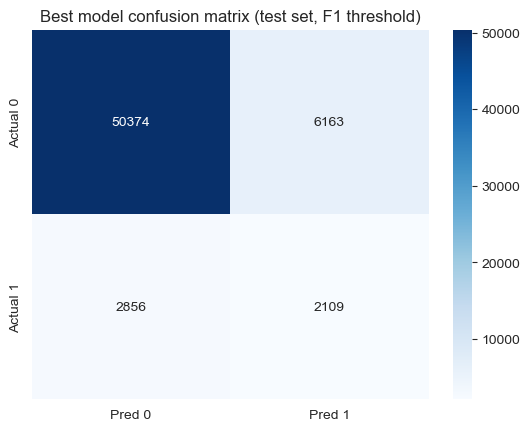

In [129]:
best = results_df.iloc[0]
best_fs, best_name = best['Features'], best['Model']
best_entry = store[(best_fs, best_name)]
best_model = best_entry['model']
print('Best combination (chosen on validation ROC-AUC):', best_name, 'with', best_fs, 'features')
print(f"Validation ROC-AUC = {best['Val_ROC_AUC']:.4f} | Test ROC-AUC = {best['ROC_AUC']:.4f}")

A_tr_b, A_va_b, A_te_b, names_b, pipe_b = get_matrices(best_fs)
cm = confusion_matrix(y_test, (best_entry['proba'] >= best_entry['threshold']).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Pred 0', 'Pred 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.title('Best model confusion matrix (test set, F1 threshold)')
plt.show()

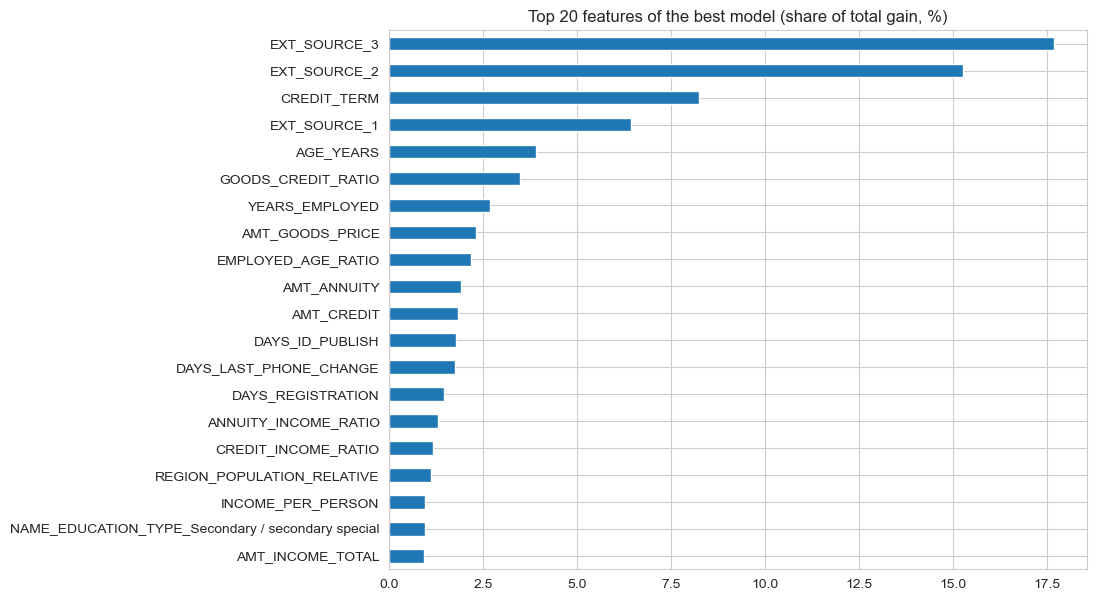

In [131]:
def clean_name(n):
    return n.replace('num__', '').replace('cat__', '').replace('missingindicator_', 'MISSING_')

if hasattr(best_model, 'feature_importances_'):
    importance = best_model.feature_importances_
else:
    importance = np.abs(best_model.coef_[0])
importance = pd.Series(importance / np.sum(importance) * 100, index=[clean_name(n) for n in names_b])
importance.sort_values(ascending=False).head(20).sort_values().plot.barh(
    figsize=(9, 7), title='Top 20 features of the best model (share of total gain, %)')
plt.show()

In [133]:
base_row = results_df[(results_df['Features'] == 'Base') & (results_df['Model'] == 'LogReg')].iloc[0]
print(f"Baseline ROC-AUC: {base_row['ROC_AUC']:.4f}  |  Best ROC-AUC: {best['ROC_AUC']:.4f}  |  Gain: {best['ROC_AUC'] - base_row['ROC_AUC']:+.4f}")
print(f"Baseline PR-AUC : {base_row['PR_AUC']:.4f}  |  Best PR-AUC : {best['PR_AUC']:.4f}  |  Gain: {best['PR_AUC'] - base_row['PR_AUC']:+.4f}")
print(f"Baseline Recall : {base_row['Recall']:.4f}  |  Best Recall : {best['Recall']:.4f}")

Baseline ROC-AUC: 0.7494  |  Best ROC-AUC: 0.7713  |  Gain: +0.0219
Baseline PR-AUC : 0.2314  |  Best PR-AUC : 0.2624  |  Gain: +0.0311
Baseline Recall : 0.4560  |  Best Recall : 0.4248


## 12b. Over-fitting and under-fitting check
- **Under-fitting** = train and validation AUC are both low (the model is too simple or too constrained).
- **Over-fitting** = train AUC is far above validation AUC **and** validation gets worse as the model gets more complex.

Boosting models always show a train-validation gap; what matters is whether validation stops improving or falls. Four checks: (1) train / validation / test AUC, (2) AUC against the number of trees, (3) a model-complexity sweep (`num_leaves`), (4) a learning curve (does more data help?). Train AUC is measured on a random 60,000-row subsample of the training set to save time.

In [136]:
def auc_of(model, A, y_):
    return roc_auc_score(y_, model.predict_proba(A)[:, 1])

rng_fit = np.random.RandomState(RANDOM_STATE)
sub_tr = rng_fit.choice(len(A_tr_b), min(60000, len(A_tr_b)), replace=False)
y_tr_arr = y_train.values
fit_df = pd.DataFrame([
    {'Model': best_name, 'Train': roc_auc_score(y_tr_arr[sub_tr], best_model.predict_proba(A_tr_b[sub_tr])[:, 1]),
     'Validation': auc_of(best_model, A_va_b, y_val), 'Test': auc_of(best_model, A_te_b, y_test)},
    {'Model': 'Baseline LogReg', 'Train': auc_of(baseline, A_train, y_train),
     'Validation': auc_of(baseline, A_val, y_val), 'Test': auc_of(baseline, A_test, y_test)}])
fit_df['Gap_train_minus_val'] = fit_df['Train'] - fit_df['Validation']
fit_df['Gap_val_minus_test'] = fit_df['Validation'] - fit_df['Test']
fit_df.round(4)

,Model,Train,Validation,Test,Gap_train_minus_val,Gap_val_minus_test
0,LightGBM_tuned,0.8184,0.7684,0.7713,0.0500,-0.0028
1,Baseline LogReg,0.7498,0.7472,0.7494,0.0026,-0.0022


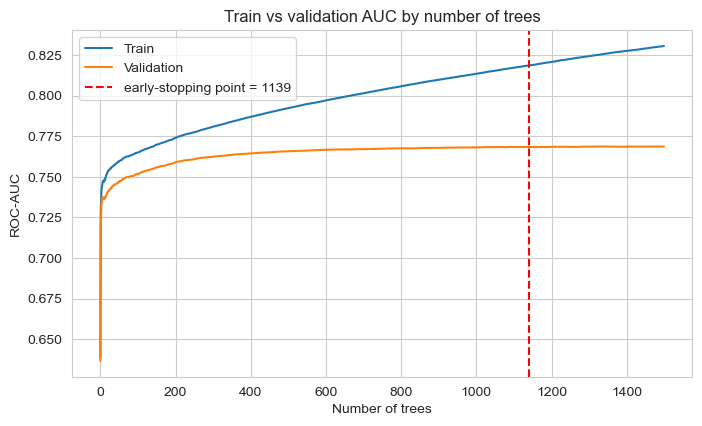

Validation AUC at the stopping point: 0.7684 | at the end: 0.7686 | best anywhere: 0.7687 (tree 1336)


In [138]:
# 2) AUC against the number of trees (the model is trained past the early-stopping point on purpose)
if isinstance(best_model, LGBMClassifier):
    bi = int(getattr(best_model, 'best_iteration_', None) or 400)
    evals = {}
    m_curve = LGBMClassifier(**{**LGB_PARAMS, **TUNED_PARAMS, 'n_estimators': min(1500, 2 * bi)})
    m_curve.fit(A_tr_b, y_train, eval_set=[(A_tr_b[sub_tr], y_tr_arr[sub_tr]), (A_va_b, y_val)],
                eval_names=['train', 'val'], callbacks=[lgb.record_evaluation(evals)])
    plt.figure(figsize=(8, 4.5))
    plt.plot(evals['train']['auc'], label='Train')
    plt.plot(evals['val']['auc'], label='Validation')
    plt.axvline(bi, color='red', linestyle='--', label=f'early-stopping point = {bi}')
    plt.xlabel('Number of trees')
    plt.ylabel('ROC-AUC')
    plt.title('Train vs validation AUC by number of trees')
    plt.legend()
    plt.show()
    v = np.array(evals['val']['auc'])
    print(f'Validation AUC at the stopping point: {v[min(bi, len(v)) - 1]:.4f} | at the end: {v[-1]:.4f} | best anywhere: {v.max():.4f} (tree {v.argmax() + 1})')
else:
    print('Tree-count curve is implemented for LightGBM only; the best model is', best_name)

,num_leaves,trees,Train,Validation,Gap
0,3,1500,0.7707,0.7600,0.0107
1,7,1344,0.7928,0.7671,0.0257
2,15,1139,0.8184,0.7684,0.0500
3,31,544,0.8233,0.7675,0.0558
4,63,330,0.8367,0.7661,0.0706
5,127,438,0.9014,0.7668,0.1346
6,255,210,0.8856,0.7645,0.1210


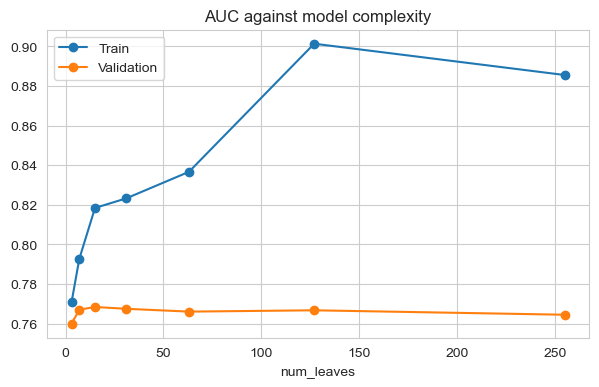

In [140]:
# 3) Complexity sweep: under-fit on the left, over-fit on the right
sweep = []
for leaves in [3, 7, 15, 31, 63, 127, 255]:
    mm = LGBMClassifier(**{**LGB_PARAMS, **TUNED_PARAMS, 'num_leaves': leaves, 'n_estimators': 1500})
    mm = fit_model(mm, A_tr_b, y_train, A_va_b, y_val)
    sweep.append({'num_leaves': leaves, 'trees': mm.best_iteration_,
                  'Train': roc_auc_score(y_tr_arr[sub_tr], mm.predict_proba(A_tr_b[sub_tr])[:, 1]),
                  'Validation': auc_of(mm, A_va_b, y_val)})
sweep_df = pd.DataFrame(sweep)
sweep_df['Gap'] = sweep_df['Train'] - sweep_df['Validation']
display(sweep_df.round(4))
sweep_df.set_index('num_leaves')[['Train', 'Validation']].plot(marker='o', figsize=(7, 4), title='AUC against model complexity')
plt.show()

,train_rows,Train,Validation,Gap
0,19680,0.9527,0.7389,0.2138
1,49201,0.8921,0.7548,0.1373
2,98402,0.8464,0.7624,0.0839
3,196804,0.8160,0.7679,0.0481


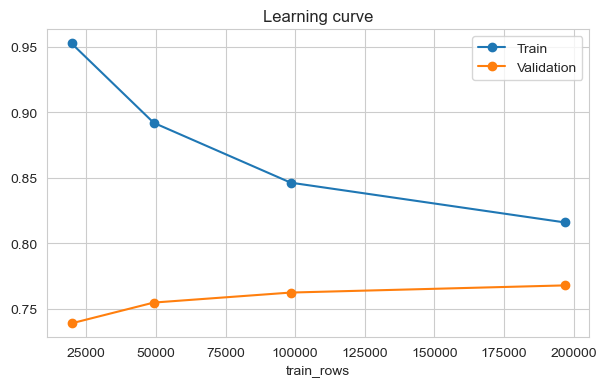

In [142]:
# 4) Learning curve: would more training data help?
lc = []
perm = rng_fit.permutation(len(A_tr_b))
n_lc_trees = int(getattr(best_model, 'best_iteration_', None) or getattr(best_model, 'best_iteration', None) or 400)
for frac in [0.1, 0.25, 0.5, 1.0]:
    idx = perm[:int(len(perm) * frac)]
    mm = LGBMClassifier(**{**LGB_PARAMS, **TUNED_PARAMS, 'n_estimators': n_lc_trees})
    mm.fit(A_tr_b[idx], y_tr_arr[idx])
    t_idx = idx[:60000]
    lc.append({'train_rows': len(idx), 'Train': roc_auc_score(y_tr_arr[t_idx], mm.predict_proba(A_tr_b[t_idx])[:, 1]),
               'Validation': auc_of(mm, A_va_b, y_val)})
lc_df = pd.DataFrame(lc)
lc_df['Gap'] = lc_df['Train'] - lc_df['Validation']
display(lc_df.round(4))
lc_df.set_index('train_rows')[['Train', 'Validation']].plot(marker='o', figsize=(7, 4), title='Learning curve')
plt.show()

**How to read it**
1. A train-validation gap of a few hundredths with a validation curve that is flat (not falling) is normal for boosting and is controlled by early stopping. A validation-test gap close to zero shows the validation set was not over-used.
2. In the complexity sweep the best `num_leaves` is where validation peaks; clearly lower values under-fit (both curves low), clearly higher values over-fit (validation falls while train keeps rising).
3. In the learning curve, if validation is still rising with more rows the model is limited by the amount of data (more tables would help), not by its complexity. If both curves had converged at a low value the model would be under-fitting.
4. Logistic Regression has almost no gap but a lower ceiling than the boosting models: it is limited by capacity (linear), not by regularisation.

## 13. Explaining the model with SHAP values
SHAP values split each prediction into the contribution of every feature (in log-odds). They are computed directly by the tree libraries (`pred_contrib` in LightGBM, `pred_contribs` in XGBoost), on a random sample of the test set.
This answers two business questions: *which factors drive risk overall?* and *why was this particular applicant flagged?*

In [146]:
def tree_contributions(model, A):
    if isinstance(model, LGBMClassifier):
        c = model.predict(A, pred_contrib=True)
    elif isinstance(model, XGBClassifier):
        c = model.get_booster().predict(xgb.DMatrix(A), pred_contribs=True)
    else:  # logistic regression: contribution = coefficient x value
        c = np.hstack([A * model.coef_[0], np.zeros((A.shape[0], 1))])
    c = np.asarray(c)
    return c[:, :-1], c[:, -1]

SHAP_N = min(5000, len(A_te_b))
shap_rs = np.random.RandomState(RANDOM_STATE)
shap_idx = shap_rs.choice(len(A_te_b), SHAP_N, replace=False)
A_s = A_te_b[shap_idx]
contrib, bias = tree_contributions(best_model, A_s)
short_names = np.array([clean_name(n) for n in names_b])
mean_abs = np.abs(contrib).mean(axis=0)
print('SHAP matrix:', contrib.shape)

SHAP matrix: (5000, 224)


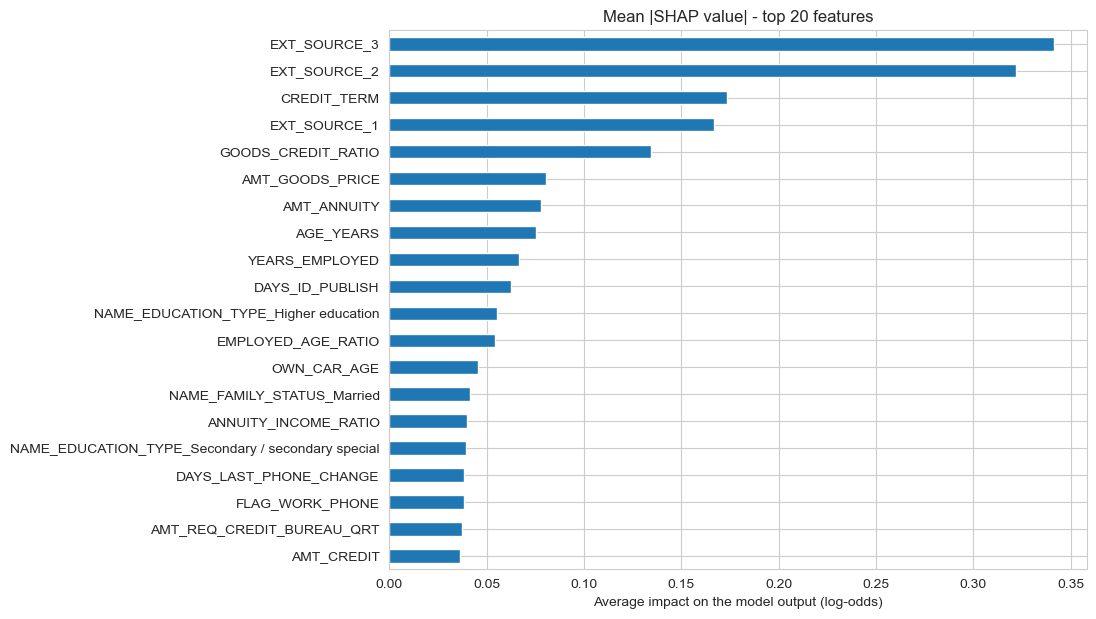

In [148]:
top_n = 20
top = np.argsort(mean_abs)[::-1][:top_n]
pd.Series(mean_abs[top], index=short_names[top]).sort_values().plot.barh(
    figsize=(9, 7), title='Mean |SHAP value| - top 20 features')
plt.xlabel('Average impact on the model output (log-odds)')
plt.show()

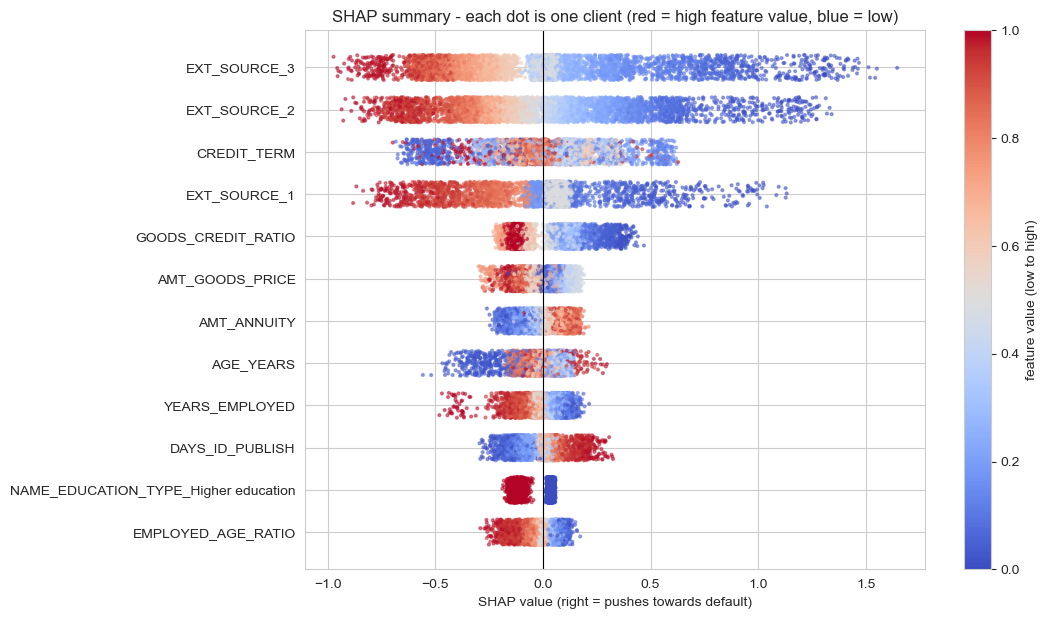

In [150]:
top12 = np.argsort(mean_abs)[::-1][:12][::-1]
fig, ax = plt.subplots(figsize=(10, 7))
for pos, j in enumerate(top12):
    rank = pd.Series(A_s[:, j]).rank(pct=True).values
    ax.scatter(contrib[:, j], pos + shap_rs.uniform(-0.3, 0.3, len(rank)), c=rank, cmap='coolwarm', s=4, alpha=0.5)
ax.axvline(0, color='k', linewidth=0.8)
ax.set_yticks(range(len(top12)))
ax.set_yticklabels(short_names[top12])
ax.set_xlabel('SHAP value (right = pushes towards default)')
ax.set_title('SHAP summary - each dot is one client (red = high feature value, blue = low)')
sm = plt.cm.ScalarMappable(cmap='coolwarm')
sm.set_array([])
fig.colorbar(sm, ax=ax, label='feature value (low to high)')
plt.show()

In [152]:
def shap_direction(j, n_bins=5):
    """Direction of a feature's effect from the SHAP values: compare the lowest and highest 20% of its values
    (robust to non-linear shapes) and report whether the pattern is monotonic."""
    v, s_ = A_s[:, j], contrib[:, j]
    if np.std(v) == 0 or np.std(s_) == 0:
        return None
    if len(np.unique(v)) <= 2:                       # yes/no flag (one-hot category or missing-value indicator)
        on = v == v.max()
        return 'flag', s_[on].mean() - s_[~on].mean(), None
    q = pd.qcut(pd.Series(v).rank(method='first'), n_bins, labels=False).values
    means = pd.Series(s_).groupby(q).mean().values
    monotone = bool(np.all(np.diff(means) >= -1e-9) or np.all(np.diff(means) <= 1e-9))
    return 'num', means, monotone

print('Main risk drivers in plain language (SHAP in log-odds, lowest 20% of values vs highest 20%):\n')
for j in np.argsort(mean_abs)[::-1][:10]:
    r = shap_direction(j)
    if r is None:
        continue
    kind, val, mono = r
    if kind == 'flag':
        word = 'INCREASE' if val > 0 else 'REDUCE'
        print(f'- {short_names[j]} (yes/no flag): when it applies, default risk tends to {word} (average impact {mean_abs[j]:.3f})')
    else:
        word = 'INCREASE' if val[-1] > val[0] else 'REDUCE'
        shape = 'monotonic' if mono else 'NON-MONOTONIC (see dependence plot)'
        print(f'- {short_names[j]}: higher values {word} default risk, {shape} '
              f'[SHAP lowest 20%: {val[0]:+.3f}, highest 20%: {val[-1]:+.3f}] (average impact {mean_abs[j]:.3f})')

Main risk drivers in plain language (SHAP in log-odds, lowest 20% of values vs highest 20%):

- EXT_SOURCE_3: higher values REDUCE default risk, monotonic [SHAP lowest 20%: +0.695, highest 20%: -0.566] (average impact 0.341)
- EXT_SOURCE_2: higher values REDUCE default risk, monotonic [SHAP lowest 20%: +0.617, highest 20%: -0.510] (average impact 0.322)
- CREDIT_TERM: higher values REDUCE default risk, NON-MONOTONIC (see dependence plot) [SHAP lowest 20%: -0.066, highest 20%: -0.067] (average impact 0.173)
- EXT_SOURCE_1: higher values REDUCE default risk, NON-MONOTONIC (see dependence plot) [SHAP lowest 20%: +0.227, highest 20%: -0.394] (average impact 0.167)
- GOODS_CREDIT_RATIO: higher values REDUCE default risk, NON-MONOTONIC (see dependence plot) [SHAP lowest 20%: +0.205, highest 20%: -0.123] (average impact 0.134)
- AMT_GOODS_PRICE: higher values REDUCE default risk, NON-MONOTONIC (see dependence plot) [SHAP lowest 20%: +0.039, highest 20%: -0.112] (average impact 0.080)
- AMT_AN

### Cross-check: age in the EDA versus age in the model
The EDA shows the **marginal** default rate by age band (younger clients default more). SHAP shows the **conditional** contribution of age after accounting for all other features (employment length, ID age, income type...). These can legitimately point in different directions when features are correlated, so the table puts the three numbers side by side: the observed default rate, the average SHAP contribution of `AGE_YEARS` alone, and the average total model score (sum of all SHAP contributions).

,clients,observed_default_rate,mean_SHAP_AGE_only,mean_SHAP_all_features
age_band,,,,
"(0, 30]",715,0.1133,-0.1428,0.5826
"(30, 40]",1340,0.0888,0.0701,0.1342
"(40, 50]",1252,0.0783,0.0298,-0.0922
"(50, 60]",1078,0.0733,-0.0483,-0.2988
"(60, 120]",615,0.0520,0.0094,-0.4202


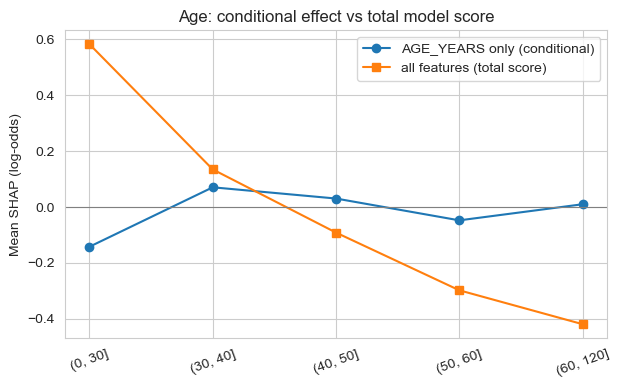

In [155]:
if 'AGE_YEARS' in list(short_names):
    ja = list(short_names).index('AGE_YEARS')
    age_raw = feature_builders[best_fs](X).loc[y_test.index].iloc[shap_idx]['AGE_YEARS'].values
    tab = pd.DataFrame({'age_band': pd.cut(age_raw, [0, 30, 40, 50, 60, 120]),
                        'default': y_test.values[shap_idx],
                        'shap_age_only': contrib[:, ja],
                        'shap_all_features': contrib.sum(axis=1)})
    tab = tab.groupby('age_band', observed=True).agg(clients=('default', 'size'), observed_default_rate=('default', 'mean'),
                                                     mean_SHAP_AGE_only=('shap_age_only', 'mean'),
                                                     mean_SHAP_all_features=('shap_all_features', 'mean'))
    display(tab.round(4))
    plt.figure(figsize=(7, 4))
    plt.plot(range(len(tab)), tab['mean_SHAP_AGE_only'].values, marker='o', label='AGE_YEARS only (conditional)')
    plt.plot(range(len(tab)), tab['mean_SHAP_all_features'].values, marker='s', label='all features (total score)')
    plt.xticks(range(len(tab)), [str(i) for i in tab.index], rotation=20)
    plt.axhline(0, color='grey', linewidth=0.8)
    plt.ylabel('Mean SHAP (log-odds)')
    plt.title('Age: conditional effect vs total model score')
    plt.legend()
    plt.show()
else:
    print('AGE_YEARS is not among the model features.')

**Reading the age table:** compare the last column with the observed default rate. If the total score follows the observed rate (higher risk for younger clients) but `mean_SHAP_AGE_only` has the opposite sign, age is being used to *correct* for other features that already capture youth-related risk (for example short employment history); that is a conditional effect, not evidence that older clients are riskier. If the two do not line up at all, report it as a limitation instead of explaining it away. In the presentation, quote the total score and the observed default rate, and describe the age-only SHAP as a conditional effect.

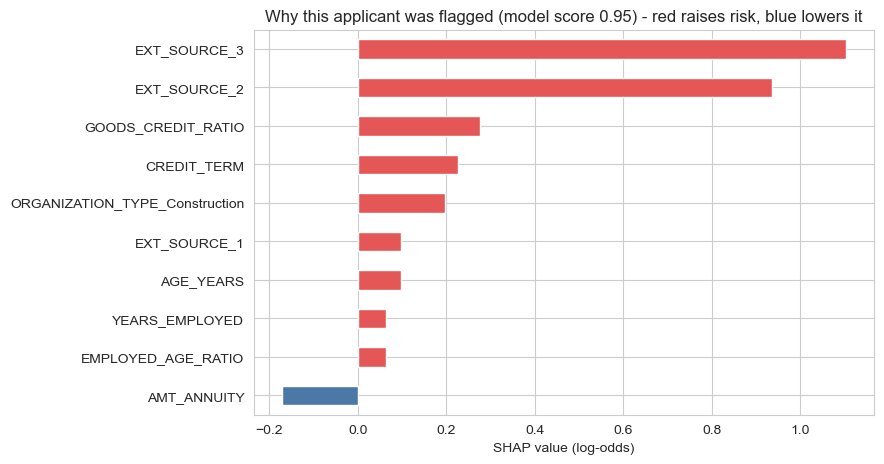

In [158]:
# Why was ONE applicant flagged? -> the highest-risk client in the sample
risk_in_sample = best_entry['proba'][shap_idx]
k = int(np.argmax(risk_in_sample))
local = pd.Series(contrib[k], index=short_names)
local = local.reindex(local.abs().sort_values(ascending=False).index).head(10).sort_values()
local.plot.barh(color=['#E45756' if v > 0 else '#4C78A8' for v in local.values], figsize=(8, 5),
                title=f'Why this applicant was flagged (model score {risk_in_sample[k]:.2f}) - red raises risk, blue lowers it')
plt.xlabel('SHAP value (log-odds)')
plt.show()

## 14. Calibration
The boosting models were trained with `scale_pos_weight` (and the baseline with `class_weight='balanced'`), so their scores rank clients well but are **not real probabilities**. A cost-based decision needs real probabilities, so the scores are calibrated with isotonic regression fitted on the **validation** set and then applied to the test set.

,Brier_score,Calibration_error_ECE
Baseline raw,0.2026,0.3398
Baseline calibrated,0.0685,0.0057
LightGBM_tuned raw,0.1842,0.3117
LightGBM_tuned calibrated,0.0670,0.0057


Average predicted default rate (calibrated): 0.08 | actual: 0.0807


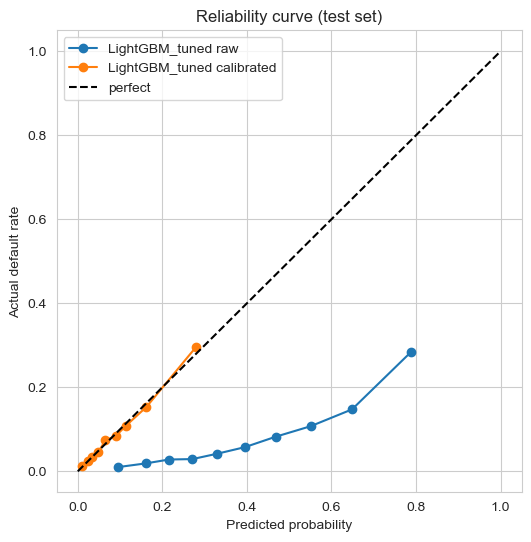

In [161]:
def calibrate(val_proba, test_proba):
    iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(val_proba, y_val)
    return iso, iso.predict(test_proba)

def ece(y_true, p, bins=10):
    frac_pos, mean_pred = calibration_curve(y_true, p, n_bins=bins, strategy='quantile')
    return float(np.mean(np.abs(frac_pos - mean_pred)))

base_entry = store[('Base', 'LogReg')]
iso_best, best_cal = calibrate(best_entry['val_proba'], best_entry['proba'])
iso_base, base_cal = calibrate(base_entry['val_proba'], base_entry['proba'])

calib_table = pd.DataFrame({
    'Brier_score': {'Baseline raw': brier_score_loss(y_test, base_entry['proba']),
                    'Baseline calibrated': brier_score_loss(y_test, base_cal),
                    f'{best_name} raw': brier_score_loss(y_test, best_entry['proba']),
                    f'{best_name} calibrated': brier_score_loss(y_test, best_cal)},
    'Calibration_error_ECE': {'Baseline raw': ece(y_test, base_entry['proba']),
                              'Baseline calibrated': ece(y_test, base_cal),
                              f'{best_name} raw': ece(y_test, best_entry['proba']),
                              f'{best_name} calibrated': ece(y_test, best_cal)},
})
display(calib_table.round(4))
print('Average predicted default rate (calibrated):', round(best_cal.mean(), 4), '| actual:', round(y_test.mean(), 4))

fig, ax = plt.subplots(figsize=(6, 6))
for label, p in [(f'{best_name} raw', best_entry['proba']), (f'{best_name} calibrated', best_cal)]:
    fp, mp = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    ax.plot(mp, fp, marker='o', label=label)
ax.plot([0, 1], [0, 1], 'k--', label='perfect')
ax.set_xlabel('Predicted probability')
ax.set_ylabel('Actual default rate')
ax.set_title('Reliability curve (test set)')
ax.legend()
plt.show()

## 15. Business impact: cost-based decision threshold
Maximising F1 treats a missed defaulter and a wrongly rejected good client as equally bad. For a lender they are not. Two **assumptions** (not in the data - replace them with the bank's own figures) turn the model into money:

- `LGD` = share of the credit amount that is lost when a loan defaults (default 45%, a common regulatory assumption).
- `MARGIN` = net profit earned on a good loan as a share of the credit amount (default 10%).

Rejecting a client with default probability *p* is worthwhile when `p x LGD > (1 - p) x MARGIN`, i.e. when `p > MARGIN / (LGD + MARGIN)`. This threshold is applied to the calibrated probabilities; nothing is tuned on the test set.
Values are in the currency units of `AMT_CREDIT` and refer to the test set (20% of the portfolio).
**Important:** LGD and margin are illustrative assumptions and `TARGET` is early payment difficulty, not a final write-off. Use this section to **compare policies with each other** (model vs baseline vs approve-everyone) and to see how the conclusion changes in the sensitivity table, not to quote the absolute money values.

In [164]:
LGD = 0.45
MARGIN = 0.10
t_star = MARGIN / (LGD + MARGIN)
credit_test = df_clean.loc[y_test.index, 'AMT_CREDIT'].values
y_te = y_test.values.astype(int)

def policy_value(proba, threshold, lgd=LGD, margin=MARGIN):
    reject = proba >= threshold
    loss_if_approved = lgd * credit_test * (y_te == 1)
    profit_if_approved = margin * credit_test * (y_te == 0)
    saved, forgone = loss_if_approved[reject].sum(), profit_if_approved[reject].sum()
    return {'Reject_rate': reject.mean(),
            'Defaulters_caught': (reject & (y_te == 1)).sum() / (y_te == 1).sum(),
            'Good_clients_rejected': (reject & (y_te == 0)).sum() / (y_te == 0).sum(),
            'Loss_avoided': saved, 'Profit_forgone': forgone, 'Net_value': saved - forgone,
            'Net_value_pct_of_portfolio_loss': (saved - forgone) / loss_if_approved.sum()}

print(f'Business threshold t* = {MARGIN:.2f} / ({LGD:.2f} + {MARGIN:.2f}) = {t_star:.3f}')
policies = {
    'Approve everyone': policy_value(np.zeros(len(y_te)), 1.0),
    'Baseline LogReg (calibrated, t*)': policy_value(base_cal, t_star),
    f'{best_name} (calibrated, t*)': policy_value(best_cal, t_star),
    f'{best_name} (F1 threshold)': policy_value(best_entry['proba'], best_entry['threshold']),
    'Perfect foresight (upper bound)': policy_value(y_te.astype(float), 0.5),
}
policy_df = pd.DataFrame(policies).T
for c in ['Loss_avoided', 'Profit_forgone', 'Net_value']:
    policy_df[c] = policy_df[c].round(0)
policy_df.round(3)

Business threshold t* = 0.10 / (0.45 + 0.10) = 0.182


,Reject_rate,Defaulters_caught,Good_clients_rejected,Loss_avoided,Profit_forgone,Net_value,Net_value_pct_of_portfolio_loss
Approve everyone,0.000,0.000,0.000,0.000000e+00,0.0,0.000000e+00,0.000
"Baseline LogReg (calibrated, t*)",0.096,0.315,0.077,3.731212e+08,232425654.0,1.406956e+08,0.113
"LightGBM_tuned (calibrated, t*)",0.092,0.338,0.071,3.845568e+08,200657315.0,1.838994e+08,0.147
LightGBM_tuned (F1 threshold),0.134,0.425,0.109,4.883136e+08,315352736.0,1.729609e+08,0.138
Perfect foresight (upper bound),0.081,1.000,0.000,1.248911e+09,0.0,1.248911e+09,1.000


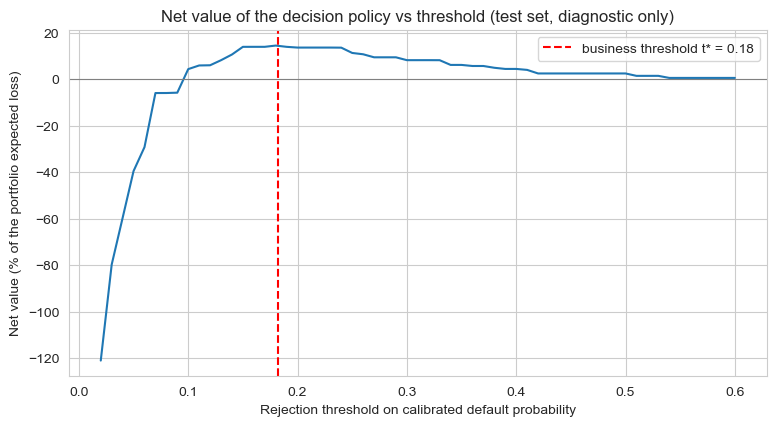

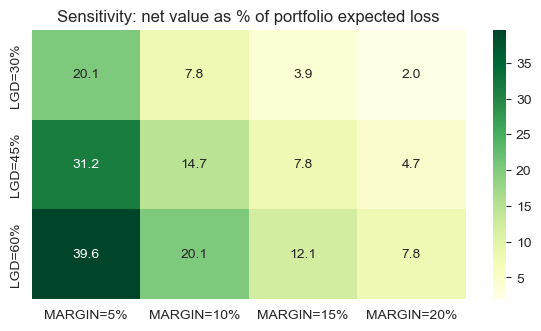

In [166]:
grid = np.linspace(0.02, 0.60, 59)
net_curve = [policy_value(best_cal, t)['Net_value_pct_of_portfolio_loss'] for t in grid]
plt.figure(figsize=(9, 4.5))
plt.plot(grid, np.array(net_curve) * 100)
plt.axvline(t_star, color='red', linestyle='--', label=f'business threshold t* = {t_star:.2f}')
plt.axhline(0, color='grey', linewidth=0.8)
plt.xlabel('Rejection threshold on calibrated default probability')
plt.ylabel('Net value (% of the portfolio expected loss)')
plt.title('Net value of the decision policy vs threshold (test set, diagnostic only)')
plt.legend()
plt.show()

lgd_grid, margin_grid = [0.30, 0.45, 0.60], [0.05, 0.10, 0.15, 0.20]
sens = pd.DataFrame({f'MARGIN={m:.0%}': [policy_value(best_cal, m / (l + m), l, m)['Net_value_pct_of_portfolio_loss'] * 100
                                         for l in lgd_grid] for m in margin_grid},
                    index=[f'LGD={l:.0%}' for l in lgd_grid])
plt.figure(figsize=(7, 3.5))
sns.heatmap(sens, annot=True, fmt='.1f', cmap='YlGn')
plt.title('Sensitivity: net value as % of portfolio expected loss')
plt.show()

## 16. Risk bands, decile analysis and lift
Lenders use scores in bands, not as a single yes/no. Clients in the test set are ranked by model score and split into 10 equal groups (decile 1 = highest risk).
- **Lift** = default rate in the decile divided by the overall default rate.
- **Cumulative gain** = share of all defaulters found when only the riskiest x% of clients are reviewed.

,clients,defaults,default_rate,avg_predicted,share_of_all_defaults,cumulative_share,lift
decile,,,,,,,
1,6151,1750,0.285,0.272,0.352,0.352,3.524
2,6150,907,0.147,0.158,0.183,0.535,1.827
3,6150,660,0.107,0.109,0.133,0.668,1.329
4,6150,507,0.082,0.073,0.102,0.770,1.021
5,6150,354,0.058,0.057,0.071,0.841,0.713
6,6150,258,0.042,0.046,0.052,0.893,0.520
7,6150,179,0.029,0.032,0.036,0.930,0.361
8,6150,173,0.028,0.027,0.035,0.964,0.348
9,6150,116,0.019,0.018,0.023,0.988,0.234


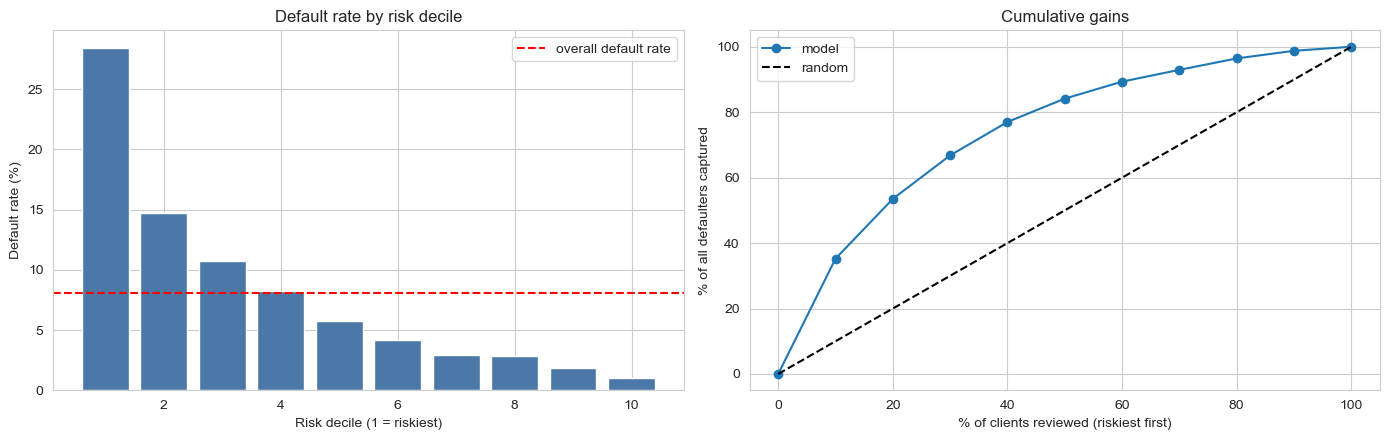

In [169]:
rank_pos = pd.Series(best_entry['proba']).rank(method='first', ascending=False)
decile = pd.qcut(rank_pos, 10, labels=range(1, 11)).astype(int).values
dec = (pd.DataFrame({'decile': decile, 'default': y_te, 'predicted_calibrated': best_cal})
       .groupby('decile').agg(clients=('default', 'size'), defaults=('default', 'sum'),
                              default_rate=('default', 'mean'), avg_predicted=('predicted_calibrated', 'mean')))
dec['share_of_all_defaults'] = dec['defaults'] / dec['defaults'].sum()
dec['cumulative_share'] = dec['share_of_all_defaults'].cumsum()
dec['lift'] = dec['default_rate'] / y_te.mean()
display(dec.round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(dec.index, dec['default_rate'] * 100, color='#4C78A8')
ax[0].axhline(y_te.mean() * 100, color='red', linestyle='--', label='overall default rate')
ax[0].set_xlabel('Risk decile (1 = riskiest)')
ax[0].set_ylabel('Default rate (%)')
ax[0].set_title('Default rate by risk decile')
ax[0].legend()
ax[1].plot([0] + list(dec.index * 10), [0] + list(dec['cumulative_share'] * 100), marker='o', label='model')
ax[1].plot([0, 100], [0, 100], 'k--', label='random')
ax[1].set_xlabel('% of clients reviewed (riskiest first)')
ax[1].set_ylabel('% of all defaulters captured')
ax[1].set_title('Cumulative gains')
ax[1].legend()
plt.tight_layout()
plt.show()

In [171]:
band_of = {1: 'Very high', 2: 'Very high', 3: 'High', 4: 'High', 5: 'Medium', 6: 'Medium', 7: 'Medium', 8: 'Low', 9: 'Low', 10: 'Low'}
actions = {'Very high': 'Decline, or approve only with collateral / guarantor',
           'High': 'Manual underwriting; lower limit or risk-based pricing',
           'Medium': 'Standard process',
           'Low': 'Fast-track / pre-approved offers'}
bands = (pd.DataFrame({'band': pd.Series(decile).map(band_of).values, 'default': y_te})
         .groupby('band').agg(clients=('default', 'size'), defaults=('default', 'sum'), default_rate=('default', 'mean')))
bands = bands.loc[['Very high', 'High', 'Medium', 'Low']]
bands['share_of_clients'] = bands['clients'] / bands['clients'].sum()
bands['share_of_all_defaults'] = bands['defaults'] / bands['defaults'].sum()
bands['suggested_action'] = [actions[b] for b in bands.index]
bands.round(3)

,clients,defaults,default_rate,share_of_clients,share_of_all_defaults,suggested_action
band,,,,,,
Very high,12301,2657,0.216,0.2,0.535,"Decline, or approve only with collateral / gua..."
High,12300,1167,0.095,0.2,0.235,Manual underwriting; lower limit or risk-based...
Medium,18450,791,0.043,0.3,0.159,Standard process
Low,18451,350,0.019,0.3,0.070,Fast-track / pre-approved offers


## 17. Fairness check: the protected attribute and its proxies
**Decision:** `CODE_GENDER` is **not used** by the model (`EXCLUDE_FROM_MODEL`). Gender is a legitimate statistical predictor, but using it directly in credit decisions is restricted by anti-discrimination rules in many jurisdictions (check the local regulation). `AGE_YEARS` is kept because it is allowed in most credit-scoring settings and carries real signal; the cost of dropping it is measured below. Note that age also enters some ratios (e.g. `EMPLOYED_AGE_RATIO`), so dropping the `AGE_YEARS` column alone does not remove all age information.

This section (1) measures what the gender exclusion cost in predictive power, and (2) audits the decisions by gender, because removing a column does not remove **proxies** (occupation, income type, education...). Metrics per group at the business threshold `t*`:
- **Approval-rate ratio** (lower / higher): the "four-fifths rule" of thumb flags values below 0.80.
- **TPR** = share of real defaulters rejected, **FPR** = share of good clients rejected. Large TPR/FPR gaps between groups mean the model makes errors of different kinds for different groups.

In [174]:
# (1) Cost of excluding gender / age: the best configuration is re-trained on alternative feature sets
X_all = df_clean.drop(columns=['TARGET', 'SK_ID_CURR'])                    # includes CODE_GENDER
variants = {'With CODE_GENDER': feature_builders[best_fs](X_all),
            'Without CODE_GENDER and AGE_YEARS': feature_builders[best_fs](X).drop(columns=['AGE_YEARS'])}
fair_rows = [{'Scenario': 'Production model (no CODE_GENDER)', 'Val_ROC_AUC': best['Val_ROC_AUC'],
              'Test_ROC_AUC': best['ROC_AUC'], 'Test_PR_AUC': best['PR_AUC']}]
variant_cal = {}
for sc, feats in variants.items():
    A_tr_f, A_va_f, A_te_f, _, _ = prepare(feats)
    m = fit_model(clone(best_model), A_tr_f, y_train, A_va_f, y_val)
    pv, pt = m.predict_proba(A_va_f)[:, 1], m.predict_proba(A_te_f)[:, 1]
    fair_rows.append({'Scenario': sc, 'Val_ROC_AUC': roc_auc_score(y_val, pv), 'Test_ROC_AUC': roc_auc_score(y_test, pt),
                      'Test_PR_AUC': average_precision_score(y_test, pt)})
    variant_cal[sc] = calibrate(pv, pt)[1]
fair_df = pd.DataFrame(fair_rows)
fair_df['Test_AUC_change_vs_production'] = fair_df['Test_ROC_AUC'] - fair_df.loc[0, 'Test_ROC_AUC']
display(fair_df.round(4))

,Scenario,Val_ROC_AUC,Test_ROC_AUC,Test_PR_AUC,Test_AUC_change_vs_production
0,Production model (no CODE_GENDER),0.7684,0.7713,0.2624,0.0000
1,With CODE_GENDER,0.7690,0.7722,0.2646,0.0009
2,Without CODE_GENDER and AGE_YEARS,0.7664,0.7696,0.2595,-0.0017


In [176]:
# (2) Audit of the decisions by gender at the business threshold t*
gender_te = df_clean.loc[y_test.index, 'CODE_GENDER'].values

def group_report(p_cal, label):
    rows = []
    for g in ['F', 'M']:
        mk = gender_te == g
        rej = p_cal[mk] >= t_star
        yy = y_te[mk]
        rows.append({'Model': label, 'Gender': g, 'Applicants': int(mk.sum()), 'Actual_default_rate': yy.mean(),
                     'Rejection_rate': rej.mean(), 'Approval_rate': 1 - rej.mean(),
                     'TPR_defaulters_rejected': rej[yy == 1].mean(), 'FPR_good_clients_rejected': rej[yy == 0].mean()})
    return pd.DataFrame(rows)

rep = pd.concat([group_report(best_cal, 'Production (no gender)'),
                 group_report(variant_cal['With CODE_GENDER'], 'With CODE_GENDER')], ignore_index=True)
display(rep.round(4))
for label, grp in rep.groupby('Model', sort=False):
    g = grp.set_index('Gender')
    appr, rej, act = g['Approval_rate'], g['Rejection_rate'], g['Actual_default_rate']
    print(f"{label}: approval-rate ratio = {appr.min() / appr.max():.2f} (four-fifths rule: >= 0.80) | "
          f"rejection-rate ratio M/F = {rej['M'] / rej['F']:.2f} | observed default-rate ratio M/F = {act['M'] / act['F']:.2f}")

,Model,Gender,Applicants,Actual_default_rate,Rejection_rate,Approval_rate,TPR_defaulters_rejected,FPR_good_clients_rejected
0,Production (no gender),F,40544,0.0699,0.0729,0.9271,0.2906,0.0565
1,Production (no gender),M,20958,0.1016,0.1294,0.8706,0.4002,0.0988
2,With CODE_GENDER,F,40544,0.0699,0.0698,0.9302,0.2807,0.0539
3,With CODE_GENDER,M,20958,0.1016,0.1519,0.8481,0.4448,0.1188


Production (no gender): approval-rate ratio = 0.94 (four-fifths rule: >= 0.80) | rejection-rate ratio M/F = 1.78 | observed default-rate ratio M/F = 1.45
With CODE_GENDER: approval-rate ratio = 0.91 (four-fifths rule: >= 0.80) | rejection-rate ratio M/F = 2.18 | observed default-rate ratio M/F = 1.45


**How to read it:** compare the rejection-rate ratio with the observed default-rate ratio. A model that ranks risk correctly will reject the higher-risk group more often, but a rejection ratio far above the default ratio means the model amplifies the difference. Excluding gender should narrow that amplification; whatever remains comes from proxies and from real differences in observed defaults. A residual gap is neither proof of discrimination nor proof of its absence: a production deployment would add a documented review of proxies and legal sign-off.

## 18. Saving the model and re-scoring raw applications
The final model, its preprocessing pipeline, the isotonic calibrator and the business threshold are saved together. `score_applications` takes rows **in the original file format**, repeats the cleaning and feature steps, and returns the calibrated default probability and the decision. The cell re-scores part of the test set from the raw data and checks that the result matches the notebook, which proves the whole chain is reproducible.

*Note:* the saved pipeline contains the custom `Capper` class, so loading it in another script requires the same class definition (move `Capper` to a small `.py` module for production use).

In [180]:
MODEL_BUNDLE = {'feature_set': best_fs, 'excluded_columns': EXCLUDE_FROM_MODEL, 'model_name': best_name,
                'preprocessing': pipe_b, 'model': best_model, 'calibrator': iso_best,
                'reject_threshold': t_star, 'lgd': LGD, 'margin': MARGIN}
joblib.dump(MODEL_BUNDLE, MODEL_PATH)
print('Saved:', MODEL_PATH)

def score_applications(raw_df, bundle):
    """raw_df: rows in the ORIGINAL Dataset2.csv format. Returns calibrated default probability and a decision."""
    d = raw_df.copy()
    d['DAYS_EMPLOYED_ANOM'] = (d['DAYS_EMPLOYED'] == 365243).astype(int)
    d['DAYS_EMPLOYED'] = d['DAYS_EMPLOYED'].replace(365243, np.nan)
    d['AGE_YEARS'] = -d['DAYS_BIRTH'] / 365
    d['YEARS_EMPLOYED'] = -d['DAYS_EMPLOYED'] / 365
    feats = feature_builders[bundle['feature_set']](d.reindex(columns=X.columns))
    A = bundle['preprocessing'].transform(feats).astype(np.float32)
    p_cal = bundle['calibrator'].predict(bundle['model'].predict_proba(A)[:, 1])
    return pd.DataFrame({'default_probability': p_cal,
                         'decision': np.where(p_cal >= bundle['reject_threshold'], 'REJECT / REVIEW', 'APPROVE')}, index=raw_df.index)

loaded = joblib.load(MODEL_PATH)
n_chk = min(2000, len(y_test))
scored = score_applications(df.loc[y_test.index[:n_chk]], loaded)
assert np.allclose(scored['default_probability'].values, best_cal[:n_chk], atol=1e-6), 'raw re-scoring does not match the notebook'
print(f'Re-scored {n_chk} raw test rows from the saved file: identical to the notebook results.')
scored.head()

Saved: loan_default_model.joblib
Re-scored 2000 raw test rows from the saved file: identical to the notebook results.


,default_probability,decision
180595,0.094213,APPROVE
186424,0.066859,APPROVE
103500,0.066859,APPROVE
133153,0.066859,APPROVE
211902,0.090159,APPROVE


## 19. Conclusions
The cell below prints the final headline numbers from the runs above, so the summary always matches the results.

In [183]:
b_ci = boot_table[(boot_table['Features'] == best_fs) & (boot_table['Model'] == best_name)].iloc[0]
cv_best = cv_table[cv_table['Model'] == best_name]
bv = policies[f'{best_name} (calibrated, t*)']
fm = fit_df.iloc[0]
print(f"Default rate in the portfolio: {y.mean():.1%} ({len(y):,} loans)")
print(f"Baseline (LogReg, base features): test ROC-AUC {base_row['ROC_AUC']:.3f}, PR-AUC {base_row['PR_AUC']:.3f}")
print(f"Best model ({best_name}, {best_fs}, gender excluded): test ROC-AUC {best['ROC_AUC']:.3f} "
      f"(95% CI {b_ci['CI_low']:.3f}-{b_ci['CI_high']:.3f}), PR-AUC {best['PR_AUC']:.3f}")
print(f"Gain over baseline: {b_ci['Gain_vs_baseline']:+.4f} ROC-AUC (95% CI {b_ci['Gain_CI_low']:+.4f} to {b_ci['Gain_CI_high']:+.4f}) "
      f"-> {'statistically clear' if b_ci['Gain_significant'] else 'not clearly different from the baseline'}")
if (fs_star, 'LightGBM') in boot_store and (fs_star, 'LightGBM_tuned') in boot_store:
    dt = boot_store[(fs_star, 'LightGBM_tuned')] - boot_store[(fs_star, 'LightGBM')]
    print(f"Tuning gain (tuned vs default LightGBM): {dt.mean():+.4f} ROC-AUC (95% CI {np.percentile(dt, 2.5):+.4f} to {np.percentile(dt, 97.5):+.4f}) "
          f"-> {'small in practice' if abs(dt.mean()) < 0.005 else 'material'}")
if len(cv_best):
    print(f"Cross-validated ROC-AUC of {best_name}: {cv_best.iloc[0]['CV_ROC_AUC_mean']:.3f} +/- {cv_best.iloc[0]['CV_ROC_AUC_std']:.3f}")
print(f"Fit check: train {fm['Train']:.3f} | validation {fm['Validation']:.3f} | test {fm['Test']:.3f} "
      f"(train-validation gap {fm['Gap_train_minus_val']:.3f}, validation-test gap {fm['Gap_val_minus_test']:+.3f})")
print(f"Riskiest 20% of clients (deciles 1-2) contain {dec['cumulative_share'].iloc[1]:.0%} of all defaulters "
      f"(lift {dec['lift'].iloc[0]:.1f}x in the top decile)")
print(f"Illustrative business policy (reject when calibrated p >= {t_star:.2f}; LGD/margin are assumptions): rejects {bv['Reject_rate']:.1%} of applicants, "
      f"catches {bv['Defaulters_caught']:.0%} of defaulters, net value = {bv['Net_value_pct_of_portfolio_loss']:.1%} of the portfolio expected loss.")
g = rep[rep['Model'] == 'Production (no gender)'].set_index('Gender')
print(f"Fairness (gender not used): approval-rate ratio {g['Approval_rate'].min() / g['Approval_rate'].max():.2f}, "
      f"rejection-rate ratio M/F {g['Rejection_rate']['M'] / g['Rejection_rate']['F']:.2f} "
      f"(observed default-rate ratio M/F {g['Actual_default_rate']['M'] / g['Actual_default_rate']['F']:.2f}); "
      f"AUC cost of excluding gender {fair_df.loc[0, 'Test_ROC_AUC'] - fair_df.loc[1, 'Test_ROC_AUC']:+.4f}")

Default rate in the portfolio: 8.1% (307,507 loans)
Baseline (LogReg, base features): test ROC-AUC 0.749, PR-AUC 0.231
Best model (LightGBM_tuned, +Financial, gender excluded): test ROC-AUC 0.771 (95% CI 0.764-0.778), PR-AUC 0.262
Gain over baseline: +0.0221 ROC-AUC (95% CI +0.0188 to +0.0254) -> statistically clear
Tuning gain (tuned vs default LightGBM): +0.0037 ROC-AUC (95% CI +0.0022 to +0.0054) -> small in practice
Cross-validated ROC-AUC of LightGBM_tuned: 0.766 +/- 0.003
Fit check: train 0.818 | validation 0.768 | test 0.771 (train-validation gap 0.050, validation-test gap -0.003)
Riskiest 20% of clients (deciles 1-2) contain 54% of all defaulters (lift 3.5x in the top decile)
Illustrative business policy (reject when calibrated p >= 0.18; LGD/margin are assumptions): rejects 9.2% of applicants, catches 34% of defaulters, net value = 14.7% of the portfolio expected loss.
Fairness (gender not used): approval-rate ratio 0.94, rejection-rate ratio M/F 1.78 (observed default-rate ra

### Limitations (to state openly in the presentation)
1. **Single table.** Only `application_data` was provided. The data dictionary also describes `previous_application`, and bureau / instalment history would normally add a lot of predictive power. The model's ceiling is limited by the data, not by the algorithm.
2. **Target definition.** `TARGET = 1` is "late by more than *X* days in one of the first *Y* instalments"; *X* and *Y* are not disclosed, so this is early payment difficulty, not necessarily a final loss.
3. **No dates.** All `DAYS_*` columns are relative to the application date, so an out-of-time (future) validation is impossible. Performance in a different period or market could be lower.
4. **Business assumptions.** LGD and margin are assumptions, not data. The sensitivity table in section 15 shows how the conclusion changes; the bank's real figures should replace them.
5. **Opaque features.** `EXT_SOURCE_1/2/3` are normalised external scores of unknown origin, and some dictionary descriptions look inconsistent (e.g. `FLAG_WORK_PHONE` and `FLAG_PHONE` are both described as "home phone"), so they are interpreted with care.
6. **Fairness.** Gender is excluded from the model, but proxies (occupation, education, income type) remain and age is still used (also inside some ratios). Section 17 audits the outcome by gender; a production model needs a documented review and legal sign-off.
7. **Calibration** is fitted on one validation split; it should be re-checked periodically.
8. **Small differences between models.** The boosting variants differ by a few thousandths of AUC, so the exact choice among them matters less than the data: check the learning curve in Section 12b (validation still rising with more rows means the model is data-limited).
9. **Explanations are conditional.** SHAP shows what the model does given all other features; it explains the model, not causal effects (see the age cross-check in Section 13).

### Recommended next steps
- Add the previous-application, bureau and instalment tables (aggregated per client) and re-run the same pipeline.
- Validate out-of-time when application dates are available.
- Replace the assumed LGD and margin by the bank's figures and re-run section 15.
- Monitor stability (PSI) and re-calibrate regularly; document the decision policy and the reasons given to declined clients (SHAP provides them).